> **Versión de referencia (docente).** Es el mismo notebook con las 10 celdas de ejercicio ya completadas con la solución y **con todas las salidas ejecutadas**, para revisar de un vistazo qué debe imprimir cada test y qué figuras aparecen. El notebook que se entrega a los estudiantes es `SGP_Clase6_4PCS_RANSAC.ipynb`.


# Registro *featureless* con 4PCS y RANSAC para primitivas

**Procesamiento Geométrico y Análisis de Formas — Tutorial de la Clase 6**

---

En este tutorial vas a implementar, desde cero y solo con NumPy/SciPy, dos algoritmos que
comparten una misma idea y resuelven problemas distintos:

| | Parte I | Parte II |
|---|---|---|
| Problema | alinear dos nubes con pose inicial arbitraria | encontrar planos, esferas y cilindros dentro de una nube |
| Algoritmo | **4PCS** (Aiger, Mitra & Cohen‑Or, SIGGRAPH 2008) | **RANSAC** para primitivas (Schnabel et al. 2007) |
| Hipótesis | una transformación rígida $T \in SE(3)$ | los parámetros de una primitiva |
| Puntuación | **LCP**: cuántos puntos de $P$ caen sobre $Q$ | **consenso**: cuántos puntos caen sobre la superficie |

La frase que hay que llevarse del tutorial es que **ambos son el mismo estimador**: *máximo
consenso*. Se genera una hipótesis a partir de una muestra mínima, se cuenta cuántos datos la
apoyan, y se repite lo suficiente como para que al menos una muestra haya sido limpia. Lo que
cambia entre 4PCS y RANSAC clásico es únicamente **cómo se genera la hipótesis**.

## Plan (≈120 minutos)

| # | Sección | Min |
|---|---|---|
| 0 | Preparación: datos sintéticos y visualización | 10 |
| 1.1 | El problema y la medida LCP — **Ej. 1** | 10 |
| 1.2 | Por qué una base *ancha* — **Ej. 2** | 10 |
| 1.3 | Invariantes afines de 4 puntos coplanares — **Ej. 3** | 12 |
| 1.4 | El truco del punto intermedio: `FindCongruent` — **Ej. 4** | 18 |
| 1.5 | El bucle 4PCS completo — **Ej. 5** | 12 |
| 1.6 | Regímenes difíciles y aceleración con normales — **Ej. 6** | 8 |
| 2.1 | RANSAC como maximización de consenso — **Ej. 7** | 8 |
| 2.2 | Ajuste de un plano — **Ej. 8** | 10 |
| 2.3 | Esfera y cilindro; por qué el cilindro necesita normales — **Ej. 9** | 14 |
| 2.4 | Degeneraciones y extracción secuencial — **Ej. 10** | 12 |
| 3 | Cierre y discusión | 6 |

**10 ejercicios**, cada uno con una celda `TODO` y un test automático (`assert`). Al final del
notebook hay una sección **Soluciones** con celdas plegadas: si te atascas, la ejecutas y
sigues adelante.

> **Requisitos:** solo NumPy, SciPy y Matplotlib (ya vienen en Colab). No hace falta Open3D ni
> instalar nada. Entorno recomendado: *Runtime → CPU*. El notebook completo corre en unos 6–8
> minutos de cómputo.

## 0. Preparación

Ejecuta las tres celdas siguientes sin modificarlas. Definen:

* utilidades de visualización 3D con Matplotlib,
* un generador de **nubes sintéticas** (una "estrella" asimétrica y una **fachada** casi plana),
* un simulador de **escaneos parciales** por eliminación de puntos ocultos (Katz et al. 2007),
  que produce dos vistas de la misma superficie con solapamiento parcial y una transformación
  rígida *ground truth* exacta.

In [ ]:
# @title 0.1 — Imports y utilidades de visualización (ejecutar)
import numpy as np, time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D            # noqa: F401
from scipy.spatial import cKDTree, ConvexHull

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 110

def _equal_axes(ax, X):
    c = X.mean(0); r = np.abs(X - c).max()
    ax.set_xlim(c[0]-r, c[0]+r); ax.set_ylim(c[1]-r, c[1]+r); ax.set_zlim(c[2]-r, c[2]+r)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])

def show_clouds(clouds, colors=None, labels=None, title="", s=2, views=((20, 30), (20, 120)),
                extra=None):
    """Dibuja una lista de nubes desde 2 puntos de vista."""
    colors = colors or ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    allX = np.vstack(clouds)
    fig = plt.figure(figsize=(4.4*len(views), 4.4))
    for a, (el, az) in enumerate(views):
        ax = fig.add_subplot(1, len(views), a+1, projection="3d")
        for i, X in enumerate(clouds):
            ax.scatter(*X.T, s=s, c=colors[i % len(colors)], lw=0,
                       label=(labels[i] if labels and a == 0 else None))
        if extra is not None:
            extra(ax)
        _equal_axes(ax, allX); ax.view_init(el, az)
        if a == 0 and labels: ax.legend(loc="upper left", markerscale=4, fontsize=8)
    fig.suptitle(title); fig.subplots_adjust(wspace=0.02, top=0.92); plt.show()

def show_segmentation(X, seg, title=""):
    """seg: entero por punto; -1 = sin asignar (gris)."""
    cmap = plt.get_cmap("tab10")
    fig = plt.figure(figsize=(9, 4.4))
    for a, (el, az) in enumerate(((22, 35), (22, 125))):
        ax = fig.add_subplot(1, 2, a+1, projection="3d")
        for k in np.unique(seg):
            m = seg == k
            c = (0.75, 0.75, 0.75) if k < 0 else cmap(k % 10)
            ax.scatter(*X[m].T, s=2, color=c, lw=0)
        _equal_axes(ax, X); ax.view_init(el, az)
    fig.suptitle(title); fig.subplots_adjust(wspace=0.02, top=0.92); plt.show()

print("listo")

listo


In [ ]:
# @title 0.2 — Nubes sintéticas y simulación de escaneos parciales (ejecutar)

def blob_cloud(n=4000, n_bumps=7, seed=7):
    """Superficie estrellada asimétrica: sin simetrías que confundan al registro."""
    rng = np.random.default_rng(seed)
    U = rng.normal(size=(n_bumps, 3)); U /= np.linalg.norm(U, axis=1, keepdims=True)
    amp = rng.uniform(0.20, 0.55, n_bumps)
    wid = rng.uniform(0.15, 0.45, n_bumps)
    v = rng.normal(size=(n, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True)
    r = np.ones(n)
    for k in range(n_bumps):
        r += amp[k]*np.exp(-((1 - v @ U[k])/wid[k])**2)
    P = v * r[:, None] * np.array([1.0, 0.85, 1.25])     # elongación: rompe la esfericidad
    return P - P.mean(0)

def facade_cloud(n=4000, seed=0):
    """Dos planos casi perpendiculares con micro-relieve: el régimen 'sin rasgos'."""
    rng = np.random.default_rng(seed)
    k = n//2
    a = np.stack([rng.uniform(-1, 1, k), rng.uniform(-.6, .6, k), np.zeros(k)], 1)
    b = np.stack([np.full(n-k, 1.0), rng.uniform(-.6, .6, n-k), rng.uniform(0, .8, n-k)], 1)
    P = np.vstack([a, b])
    P[:, 2] += 0.02*np.sin(6*P[:, 0])*np.sin(6*P[:, 1])
    return P - P.mean(0)

def hidden_point_removal(P, camera, gamma=3.0):
    """Katz, Tal & Basri 2007: 'spherical flip' + envolvente convexa.
    Devuelve los índices de los puntos visibles desde `camera`."""
    D = P - camera
    d = np.linalg.norm(D, axis=1)
    R = d.max() * (10 ** gamma)
    F = D + D*((2*(R - d)/d)[:, None])
    hull = ConvexHull(np.vstack([F, np.zeros(3)]))
    idx = hull.vertices
    return np.sort(idx[idx < len(P)])

def random_rotation(rng):
    Qm, R = np.linalg.qr(rng.normal(size=(3, 3)))
    Qm *= np.sign(np.diag(R))
    if np.linalg.det(Qm) < 0: Qm[:, 0] *= -1
    return Qm

def apply_T(T, X):
    """Aplica una transformación homogénea 4x4 a una nube (N,3)."""
    return X @ T[:3, :3].T + T[:3, 3]

def make_scan_pair(cloud, dphi_deg=60.0, noise=0.0, outlier_frac=0.0, seed=0):
    """Dos vistas parciales de `cloud` separadas dphi_deg, con ruido y outliers opcionales.
    Devuelve (P, Q, T_gt) donde T_gt es la transformación que lleva P al sistema de Q."""
    rng = np.random.default_rng(seed)
    c = cloud.mean(0); rad = np.linalg.norm(cloud - c, axis=1).max()
    diag = np.linalg.norm(cloud.max(0) - cloud.min(0))
    def view(phi):
        cam = c + 4*rad*np.array([np.cos(phi), np.sin(phi), 0.35])
        return cloud[hidden_point_removal(cloud, cam)]
    def perturb(X):
        X = X + noise*diag*rng.normal(size=X.shape) if noise > 0 else X.copy()
        if outlier_frac > 0:
            k = int(outlier_frac*len(X))
            X = np.vstack([X, rng.uniform(cloud.min(0), cloud.max(0), (k, 3))])
        return X
    P, Q = perturb(view(0.0)), perturb(view(np.deg2rad(dphi_deg)))
    R, t = random_rotation(rng), rng.uniform(-1, 1, 3)*rad
    P = P @ R.T + t                       # ponemos P en una pose arbitraria
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = t
    return P, Q, np.linalg.inv(T)

def city_cloud(n=6000, n_boxes=9, seed=3):
    """Escaneo aereo estilizado: suelo plano + bloques rectangulares (el regimen 'sin rasgos')."""
    rng = np.random.default_rng(seed)
    boxes = [(rng.uniform(-.85, .85), rng.uniform(-.85, .85), rng.uniform(.10, .22),
              rng.uniform(.10, .22), rng.uniform(.10, .35)) for _ in range(n_boxes)]
    ng = n//2
    G = np.stack([rng.uniform(-1, 1, ng), rng.uniform(-1, 1, ng), np.zeros(ng)], 1)
    keep = np.ones(ng, bool)
    for cx, cy, w, d, h in boxes:
        keep &= ~((np.abs(G[:, 0]-cx) < w) & (np.abs(G[:, 1]-cy) < d))
    pts, per = [G[keep]], (n-ng)//len(boxes)
    for cx, cy, w, d, h in boxes:
        k = per//2; m = per-k
        top = np.stack([rng.uniform(cx-w, cx+w, k), rng.uniform(cy-d, cy+d, k),
                        np.full(k, h)], 1)
        side = np.empty((m, 3)); wch = rng.integers(0, 4, m)
        u = rng.uniform(0, 1, m)
        side[:, 2] = rng.uniform(0, h, m)
        side[:, 0] = np.where(wch == 0, cx-w, np.where(wch == 1, cx+w, cx-w+2*w*u))
        side[:, 1] = np.where(wch < 2, cy-d+2*d*u, np.where(wch == 2, cy-d, cy+d))
        pts += [top, side]
    P = np.vstack(pts)
    return P - P.mean(0)

def make_scan_pair2(cloud, dphi_deg=45.0, crop=0.35, noise=0.0, outlier_frac=0.0, seed=0):
    """Como make_scan_pair, pero recorta cada vista a un semiespacio para controlar
    el solapamiento (util cuando la vista desde arriba lo ve casi todo)."""
    rng = np.random.default_rng(seed)
    c = cloud.mean(0); rad = np.linalg.norm(cloud-c, axis=1).max()
    diag = np.linalg.norm(cloud.max(0)-cloud.min(0))
    def view(phi, sign):
        cam = c + 4*rad*np.array([np.cos(phi), np.sin(phi), 1.2])
        V = cloud[hidden_point_removal(cloud, cam)]
        return V[sign*V[:, 0] < crop*rad]
    def perturb(X):
        X = X + noise*diag*rng.normal(size=X.shape) if noise > 0 else X.copy()
        if outlier_frac > 0:
            k = int(outlier_frac*len(X))
            X = np.vstack([X, rng.uniform(cloud.min(0), cloud.max(0), (k, 3))])
        return X
    P, Q = perturb(view(0.0, 1)), perturb(view(np.deg2rad(dphi_deg), -1))
    R, t = random_rotation(rng), rng.uniform(-1, 1, 3)*rad
    P = P @ R.T + t
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = t
    return P, Q, np.linalg.inv(T)

def estimate_normals(P, k=20):
    """Normales por PCA sobre los k vecinos. Sin orientación global consistente."""
    _, idx = cKDTree(P).query(P, k=min(k, len(P)))
    N = np.empty_like(P)
    for i, nb in enumerate(idx):
        X = P[nb] - P[nb].mean(0)
        N[i] = np.linalg.svd(X, full_matrices=False)[2][-1]
    return N

def rot_trans_error(T, Tgt, scale=1.0):
    """(error angular en grados, error de traslación relativo a `scale`)."""
    R = T[:3, :3] @ Tgt[:3, :3].T
    ang = np.degrees(np.arccos(np.clip((np.trace(R)-1)/2, -1, 1)))
    return ang, float(np.linalg.norm(T[:3, 3]-Tgt[:3, 3])/scale)

print("listo")

listo


|P| = 2205   |Q| = 2072   diagonal = 4.887   δ = 0.0586


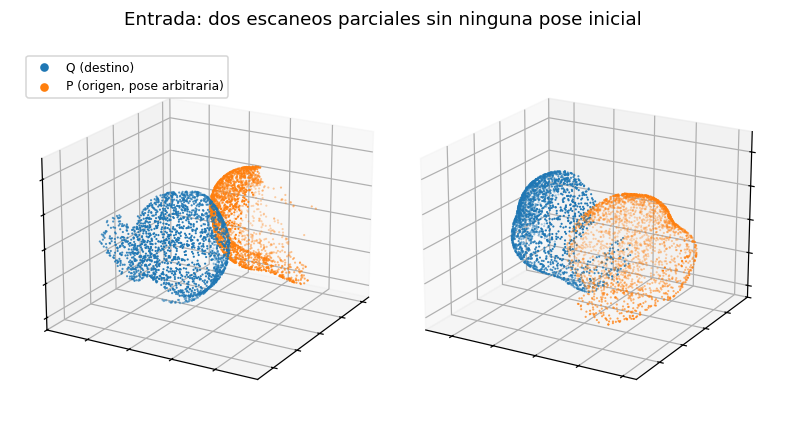

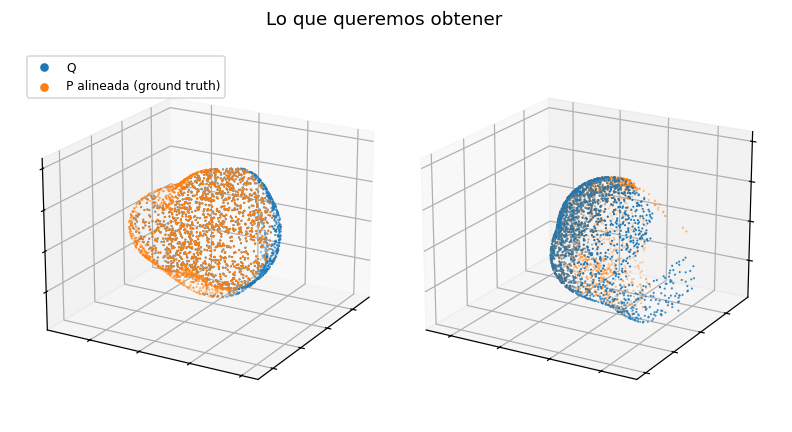

In [ ]:
# @title 0.3 — Generamos el par de escaneos de trabajo (ejecutar)
SHAPE = blob_cloud(4000)
P, Q, T_GT = make_scan_pair(SHAPE, dphi_deg=60.0, seed=1)
DIAG  = float(np.linalg.norm(Q.max(0) - Q.min(0)))       # diagonal del bounding box
DELTA = 0.012*DIAG                                       # tolerancia δ del LCP

print(f"|P| = {len(P)}   |Q| = {len(Q)}   diagonal = {DIAG:.3f}   δ = {DELTA:.4f}")
show_clouds([Q, P], labels=["Q (destino)", "P (origen, pose arbitraria)"],
            title="Entrada: dos escaneos parciales sin ninguna pose inicial")
show_clouds([Q, apply_T(T_GT, P)], labels=["Q", "P alineada (ground truth)"],
            title="Lo que queremos obtener")

---
# Parte I — Registro *featureless* con 4PCS

## 1.1 El problema y la medida LCP

Dadas $P\subset\mathbb{R}^3$ ($|P|=m$) y $Q\subset\mathbb{R}^3$ ($|Q|=n$), capturadas desde
posiciones arbitrarias y con solapamiento parcial, buscamos $T\in SE(3)$ que alinee la parte
común. Sin pose inicial, ICP no sirve: cae en un mínimo local. Hace falta *registro global*.

La receta dominante es

```
muestrear → describir cada punto → emparejar descriptores → RANSAC → ICP
```

y falla exactamente donde más se la necesita: superficies planas o sin rasgos (fachadas,
escaneos aéreos), ruido no gaussiano de escáner, outliers, agujeros. En una fachada **no hay
nada distintivo que describir**: todos los descriptores son casi iguales y el emparejamiento
se vuelve aleatorio.

4PCS elimina los pasos 2 y 3. Sustituye la evidencia **local** (*¿se parece la vecindad de $p$
a la de $q$?*) por evidencia **global**:

$$\mathrm{LCP}_\delta(T) \;=\; \bigl|\{\, p \in P \;:\; d\bigl(T(p),\,Q\bigr) \le \delta \,\}\bigr|,
\qquad T_{\text{opt}} = \arg\max_{T\in SE(3)} \mathrm{LCP}_\delta(T).$$

*Largest Common Pointset.* Cuatro propiedades que conviene tener claras:

1. **Es un conteo, no un residuo.** Un outlier suma 0 y **no penaliza**. En un residuo
   cuadrático $\sum_i \|T(p_i)-q_i\|^2$, un solo outlier lejano domina la suma. LCP es el
   estimador de **máximo consenso** — literalmente el criterio de RANSAC.
2. **Es global.** No pregunta si dos vecindades se parecen; pregunta si una nube cae sobre la
   otra.
3. **Outliers y no‑solapamiento son lo mismo para ella:** puntos de $P$ sin correspondiente en
   $Q$. Simplemente no cuentan.
4. **Necesita $\delta$.** Es el único parámetro realmente crítico: codifica la incertidumbre
   posicional esperada (típicamente el espaciado del muestreo, o ~1 % de la diagonal del
   *bounding box*). Muy chico ⇒ la pose correcta no se detecta; muy grande ⇒ poses incorrectas
   puntúan alto.

Y una propiedad incómoda: evaluarla exactamente cuesta $O(m\log n)$ por hipótesis. Volveremos
sobre eso en §1.5 con la **verificación aleatorizada**.

### Ejercicio 1 (5 min) — implementar el LCP

Implementa `lcp` usando un `cKDTree` **construido sobre $Q$** (no sobre $P$: se construye una
sola vez y se reutiliza en todas las hipótesis). Devuelve la **fracción** de puntos de $P$ que
caen a distancia $\le\delta$ de $Q$, para que el valor sea comparable entre nubes de distinto
tamaño.

El argumento `sample` sirve para la verificación en dos etapas: si no es `None`, evalúa el LCP
sobre `sample` puntos de $P$ elegidos al azar en vez de sobre todo $P$.

In [ ]:
def lcp(T, P, tree_Q, delta, sample=None, rng=None):
    X = P if sample is None else P[rng.choice(len(P), min(sample, len(P)), replace=False)]
    d, _ = tree_Q.query(apply_T(T, X), k=1)
    return float(np.mean(d <= delta))
print("lcp redefinida")

lcp redefinida


In [ ]:
# --- Test del Ejercicio 1 ---------------------------------------------------
tree_Q = cKDTree(Q)
rng_t  = np.random.default_rng(0)

s_gt  = lcp(T_GT,      P, tree_Q, DELTA)
s_id  = lcp(np.eye(4), P, tree_Q, DELTA)
s_sub = lcp(T_GT,      P, tree_Q, DELTA, sample=300, rng=rng_t)

assert isinstance(s_gt, float),           "debe devolver un float"
assert 0.0 <= s_gt <= 1.0,                "debe ser una fracción en [0,1]"
assert 0.55 < s_gt < 0.85,                f"LCP del ground truth fuera de rango: {s_gt}"
assert s_id < 0.15,                       f"la pose inicial no debería puntuar alto: {s_id}"
assert abs(s_sub - s_gt) < 0.10,          "el submuestreo no debería sesgar el LCP"
print(f"OK   LCP(ground truth) = {s_gt:.3f}   LCP(pose inicial) = {s_id:.3f}   "
      f"LCP con 300 muestras = {s_sub:.3f}")
print("\nEl solapamiento real de este par es ~%.0f %%: ese es el techo del LCP." % (100*s_gt))

OK   LCP(ground truth) = 0.690   LCP(pose inicial) = 0.007   LCP con 300 muestras = 0.687

El solapamiento real de este par es ~69 %: ese es el techo del LCP.


> **Nota sobre el submuestreo.** El LCP estimado con 300 puntos al azar coincide con el
> exacto dentro de un par de puntos porcentuales. Eso **no** es casualidad: el LCP es una
> media de indicadores, así que una muestra uniforme es un estimador insesgado con error
> $O(1/\sqrt{k})$. Un residuo denso no tiene esa propiedad. Esta es la razón por la que la
> verificación aleatorizada funciona.

---

## 1.2 Por qué una base *ancha*

Una **base** es el conjunto mínimo de puntos que determina la transformación: para $SE(3)$
bastan **3 puntos no colineales**. La pregunta interesante no es cuántos puntos, sino **qué
tan separados** están.

> Si cada punto de la base tiene error posicional $\varepsilon$ y la base tiene diámetro $D$,
> el error angular de la rotación estimada es del orden de
> $$\Delta\theta \;\sim\; \frac{\varepsilon}{D}.$$

Duplicar el ancho de la base **divide a la mitad** el error angular (Goodrich, Mitchell &
Orletsky 1994 dan las cotas formales). Un descriptor local usa, por construcción,
$D \approx$ radio de la vecindad, que es pequeño: de ahí su fragilidad.

**El precio.** En *matching* parcial los puntos de la base deben caer **todos** dentro de la
región de solapamiento. Cuanto más ancha, menos probable. La elección del ancho es un
compromiso entre estabilidad y probabilidad de éxito, y por eso el algoritmo necesita una
estimación $f$ de la fracción de solapamiento.

### Ejercicio 2 (8 min) — verificar $\Delta\theta \sim \varepsilon/D$

Vamos a medirlo. El procedimiento para un ancho $D$ dado:

1. genera 3 puntos al azar dentro de una esfera de radio $D/2$ (la base "limpia"),
2. aplica una rotación conocida $R$ para obtener sus correspondientes,
3. **perturba los correspondientes** con ruido gaussiano de desviación $\varepsilon$,
4. estima $\hat R$ con `kabsch` y mide el error angular respecto de $R$,
5. promedia sobre muchas repeticiones.

`kabsch` te la damos hecha: es la solución en forma cerrada de Horn (1987) / Kabsch, con el
cuidado de forzar $\det R = +1$ para no obtener soluciones **reflejadas** (un error clásico:
una reflexión puede puntuar altísimo en LCP y arruinar el registro).

In [ ]:
# @title `kabsch` — transformación rígida óptima con correspondencias conocidas (ejecutar)
def kabsch(A, B):
    """T rígida que lleva A -> B minimizando sum ||T(a_i) - b_i||^2 (Horn 1987 / Kabsch).
    A, B: (k,3) con correspondencia i <-> i. Fuerza det(R) = +1."""
    ca, cb = A.mean(0), B.mean(0)
    H = (A - ca).T @ (B - cb)                       # covarianza cruzada
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(Vt.T @ U.T))          # <- evita soluciones reflejadas
    R = Vt.T @ np.diag([1.0, 1.0, d]) @ U.T
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = cb - R @ ca
    return T

# comprobación rápida
_r = np.random.default_rng(0)
_A = _r.normal(size=(4, 3)); _R = random_rotation(_r); _t = _r.normal(size=3)
_T = np.eye(4); _T[:3, :3] = _R; _T[:3, 3] = _t
assert np.allclose(apply_T(kabsch(_A, apply_T(_T, _A)), _A), apply_T(_T, _A), atol=1e-9)
print("kabsch OK")

kabsch OK


In [ ]:
def angular_error_vs_width(widths, eps=0.01, reps=400, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for D in widths:
        errs = []
        for _ in range(reps):
            v = rng.normal(size=(3, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True)
            A = v * (rng.uniform(0, 1, (3, 1))**(1/3)) * (D/2)
            R = random_rotation(rng)
            B = A @ R.T
            Bn = B + eps*rng.normal(size=B.shape)
            Rhat = kabsch(A, Bn)[:3, :3]
            ang = np.degrees(np.arccos(np.clip((np.trace(Rhat @ R.T)-1)/2, -1, 1)))
            errs.append(ang)
        out.append(np.mean(errs))
    return np.array(out)
print("angular_error_vs_width redefinida")

angular_error_vs_width redefinida


ancho D : [0.25 0.5  1.   2.   4.   8.  ]
error   : [16.975  8.035  4.189  2.158  0.848  0.441] grados
pendiente log-log = -1.06   (la teoría predice -1)


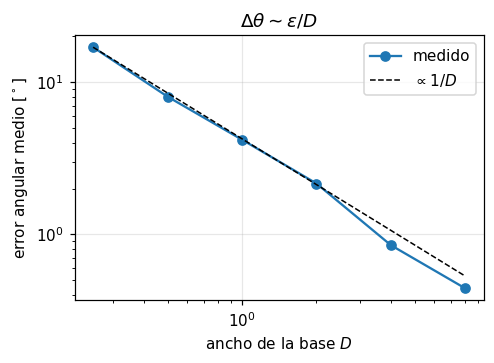

OK — una base el doble de ancha da la mitad del error angular.


In [ ]:
# --- Test del Ejercicio 2 ---------------------------------------------------
widths = np.array([0.25, 0.5, 1.0, 2.0, 4.0, 8.0])
err = angular_error_vs_width(widths, eps=0.01, reps=400, seed=0)

slope = np.polyfit(np.log(widths), np.log(err), 1)[0]
print("ancho D :", widths)
print("error   :", np.round(err, 3), "grados")
print(f"pendiente log-log = {slope:.2f}   (la teoría predice -1)")
assert np.all(np.diff(err) < 0),   "el error debe DECRECER al ensanchar la base"
assert -1.25 < slope < -0.75,      f"la pendiente debería ser ~-1, salió {slope:.2f}"

plt.figure(figsize=(4.6, 3.4))
plt.loglog(widths, err, "o-", label="medido")
plt.loglog(widths, err[0]*widths[0]/widths, "k--", lw=1, label=r"$\propto 1/D$")
plt.xlabel("ancho de la base $D$"); plt.ylabel(r"error angular medio [$^\circ$]")
plt.title(r"$\Delta\theta \sim \varepsilon / D$"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("OK — una base el doble de ancha da la mitad del error angular.")

**Lectura del gráfico.** Con el mismo ruido $\varepsilon$, la base ancha gana un orden de
magnitud de precisión sobre la angosta. Esta es la Figura 2 del paper y es toda la
justificación de por qué 4PCS insiste en bases anchas — y por qué los descriptores locales,
que son intrínsecamente de base angosta, se degradan con el ruido.

---
## 1.3 Invariantes afines de un conjunto coplanar de 4 puntos

Antes del truco algorítmico, la observación geométrica.

### El costo de buscar bases

Enumerar todas las tripletas de $P$ contra todas las de $Q$ cuesta $O(m^3n^3)$: impracticable.
La versión aleatorizada (RANSAC) no prueba todas las bases de $P$, solo unas cuantas al azar.
Si $p_g\approx f$ es la probabilidad de que un punto caiga en el solapamiento y la base tiene
$N$ puntos, la probabilidad de que una base entera caiga dentro es $p_g^N$, y para tener éxito
con probabilidad $p_s$ hacen falta

$$\boxed{\;L \;>\; \frac{\log(1-p_s)}{\log\!\left(1-p_g^{\,N}\right)}\;}\tag{Ec. 1}$$

iteraciones. Eso baja el costo a $O(m\,n^3\log n)$ y, con verificación aleatorizada, a
$O(n^3\log n)$ — **pero el $n^3$ sigue ahí**, y viene de enumerar tripletas en $Q$.

> **La observación central del paper.** Un par de tripletas define una única transformación
> rígida, pero enumerarlas cuesta $O(n^3)$. Un conjunto **especial** de 4 puntos *coplanares*
> se puede enumerar en $O(n^2)$. Toda la contribución técnica está en la palabra "especial".

Pasar de bases de 3 a bases de 4 puntos **cuesta** un factor $1.5$–$5$ en el número de
iteraciones $L$ (lo verás en el Ejercicio 5). La apuesta es que ese factor constante se paga
con creces porque el trabajo *por iteración* baja de $O(n^3)$ a $O(n^2)$: una mejora
asintótica.

### El invariante de razón

Una transformación afín $x\mapsto Ax+t$ preserva colinealidad, coplanaridad y **razones de
longitudes sobre una misma recta**. Para $a,b,c$ colineales, $\|a-b\|/\|a-c\|$ es invariante
afín. *Demostración en una línea:* si $b = a + s(c-a)$, entonces
$Ab+t = (Aa+t) + s\,[(Ac+t)-(Aa+t)]$, así que $s$ no cambia. $\square$

Toda transformación rígida es afín, así que **todo invariante afín es invariante rígido**. El
paper trabaja con invariantes afines aunque busque alineamientos rígidos porque son mucho más
baratos de calcular y definen un **superconjunto** manejable de los conjuntos rígidamente
congruentes.

### Los dos invariantes de una base coplanar

Sea $B=\{a,b,c,d\}$ coplanar y en **posición convexa**, con las rectas $\overline{ab}$ y
$\overline{cd}$ cruzándose en $e$ (siempre existe una de las 3 formas de partir 4 puntos en
dos pares que produce diagonales que se cruzan). Se define

$$r_1 = \frac{\|a-e\|}{\|a-b\|},\qquad r_2 = \frac{\|c-e\|}{\|c-d\|}.\tag{Ec. 2}$$

Estos dos números **determinan el conjunto salvo transformación afín** y se calculan en $O(1)$.

**¿Por qué 4 puntos y no 3?** Con 3 no hay invariante de razón: cualquier triángulo es
afínmente equivalente a cualquier otro. Cuatro puntos coplanares son el conjunto más pequeño
con invariantes afines no triviales. El cuarto punto **no aporta información para determinar
$T$** (con 3 basta): aporta una **firma barata que permite buscar**. Esa es la respuesta a la
pregunta de discusión clásica del paper.

### Coplanaridad aproximada

En datos reales es casi imposible que 4 puntos muestreados sean **exactamente** coplanares, así
que las rectas $\overline{ab}$ y $\overline{cd}$ no se cortan. Se usa el **segmento de mínima
distancia** entre ambas: los parámetros $s,t$ de los puntos más cercanos hacen de $r_1,r_2$, y
la longitud de ese segmento (el *gap*) mide cuán no-coplanar es la base. Se acepta la base solo
si el gap es menor que $\delta$.

### Ejercicio 3 (10 min) — invariantes afines

Implementa `affine_invariants(B)`. Debe:

1. probar las **3 particiones** de $\{0,1,2,3\}$ en dos pares;
2. para cada una, calcular los puntos más cercanos entre las dos rectas con
   `line_line_closest` (te la damos);
3. quedarse solo con las particiones en **posición convexa**, es decir $0<s<1$ y $0<t<1$
   (las diagonales se cruzan *por dentro* de ambos segmentos: es numéricamente más estable y
   hace que los puntos intermedios caigan dentro de la nube);
4. entre las válidas, devolver la de **menor gap relativo** (la más coplanar).

Devuelve `(orden, r1, r2, gap)` donde `orden` es la tupla `(i, j, k, l)` tal que
$a=B_i,\,b=B_j,\,c=B_k,\,d=B_l$.

In [ ]:
# @title `line_line_closest` — puntos más cercanos entre dos rectas (ejecutar)
def line_line_closest(p1, d1, p2, d2):
    """Rectas p1 + s*d1 y p2 + t*d2. Devuelve (s, t, e1, e2) o None si son paralelas."""
    r = p1 - p2
    a, b, c = d1 @ d1, d1 @ d2, d2 @ d2
    d, e = d1 @ r, d2 @ r
    den = a*c - b*b
    if abs(den) < 1e-12:
        return None
    s = (b*e - c*d)/den
    t = (a*e - b*d)/den
    return s, t, p1 + s*d1, p2 + t*d2

PARTICIONES = [(0, 1, 2, 3), (0, 2, 1, 3), (0, 3, 1, 2)]   # las 3 formas de partir 4 puntos

print("listo")

listo


In [ ]:
def affine_invariants(B):
    best = None
    for (i, j, k, l) in PARTICIONES:
        a, b, c, d = B[i], B[j], B[k], B[l]
        out = line_line_closest(a, b - a, c, d - c)
        if out is None:
            continue
        s, t, e1, e2 = out
        if not (0 < s < 1 and 0 < t < 1):        # posición convexa
            continue
        gap = float(np.linalg.norm(e1 - e2))
        score = gap/(np.linalg.norm(b-a) + np.linalg.norm(d-c))
        if best is None or score < best[0]:
            best = (score, (i, j, k, l), s, t, gap)
    if best is None:
        return None
    _, orden, r1, r2, gap = best
    return orden, float(r1), float(r2), float(gap)
print("affine_invariants redefinida")

affine_invariants redefinida


In [ ]:
# --- Test del Ejercicio 3 ---------------------------------------------------
rng_t = np.random.default_rng(3)

# 1) un cuadrilátero convexo exactamente coplanar en el plano z=0
B0 = np.array([[0., 0., 0.], [1.2, 0.15, 0.], [0.75, 1.05, 0.], [-0.25, 0.55, 0.]])
res = affine_invariants(B0)
assert res is not None, "debería encontrar una partición válida"
orden, r1, r2, gap = res
assert gap < 1e-9,                    f"un cuadrilátero coplanar debe tener gap ~ 0, salió {gap}"
assert 0 < r1 < 1 and 0 < r2 < 1,     "las razones deben estar en (0,1)"
assert abs(r1-r2) > 0.1,              "en este cuadrilátero las dos razones son distintas"
# la partición correcta de un cuadrilátero convexo son sus DIAGONALES: (0,2) y (1,3)
assert set(orden[:2]) == {0, 2} and set(orden[2:]) == {1, 3}, f"partición inesperada: {orden}"

# 2) invariancia: bajo transformación RÍGIDA y bajo transformación AFÍN general
Rr = random_rotation(rng_t); Tr = np.eye(4); Tr[:3, :3] = Rr; Tr[:3, 3] = rng_t.normal(size=3)
o_r, r1_r, r2_r, _ = affine_invariants(apply_T(Tr, B0))
assert abs(r1_r-r1) < 1e-9 and abs(r2_r-r2) < 1e-9, "los invariantes deben sobrevivir a T rígida"

Aff = np.array([[1.7, 0.6, 0.0], [-0.3, 0.9, 0.0], [0.4, 0.2, 1.3]])   # escala + cizalladura
o_a, r1_a, r2_a, _ = affine_invariants(B0 @ Aff.T + np.array([3., -2., 1.]))
assert abs(r1_a-r1) < 1e-8 and abs(r2_a-r2) < 1e-8, "los invariantes deben sobrevivir a una afinidad"

# 3) una base NO coplanar debe reportar un gap grande
B1 = B0.copy(); B1[3, 2] = 0.4
assert affine_invariants(B1)[3] > 0.1, "una base no coplanar debe tener gap grande"

print(f"OK   r1 = {r1:.4f}   r2 = {r2:.4f}   gap = {gap:.2e}   orden = {orden}")
print("Invariantes idénticos tras rotación+traslación y tras escala+cizalladura.")

OK   r1 = 0.3827   r2 = 0.6296   gap = 1.57e-16   orden = (0, 2, 1, 3)
Invariantes idénticos tras rotación+traslación y tras escala+cizalladura.


> **Nota.** Que los invariantes sobrevivan a una **afinidad** —no solo a un movimiento
> rígido— es a la vez la fuerza y la debilidad del método. La fuerza: buscar por $(r_1,r_2)$
> es baratísimo. La debilidad: el conjunto que encontramos es un **superconjunto** — un
> cuadrilátero cizallado tiene los mismos $r_1,r_2$ pero **no** es congruente. Por eso hará
> falta un filtro rígido explícito en §1.4.

---

## 1.4 El truco del punto intermedio: `FindCongruent`

Éste es el corazón del algoritmo. La pregunta:

> Dados $Q$ (con $n$ puntos) y dos razones $r_1,r_2$, encontrar **todos** los subconjuntos de
> 4 puntos de $Q$ cuyas razones sean $r_1$ y $r_2$.

Enumerar 4-tuplas cuesta $O(n^4)$. La idea de Huttenlocher (1991), adaptada aquí: para cada par
ordenado $(q_1,q_2)$ calcular los **puntos intermedios**

$$e_1 = q_1 + r_1\,(q_2-q_1),\qquad e_2 = q_1 + r_2\,(q_2-q_1).\tag{Ec. 3}$$

**Interpretación.** *Si* $(q_1,q_2)$ fuera el par correspondiente a $(a,b)$, el punto de
intersección del cuadrilátero tendría que estar exactamente en $e_1$. *Si* fuera el
correspondiente a $(c,d)$, ese mismo punto tendría que estar en $e_2$. En un conjunto
genuinamente congruente **los dos pares comparten el punto de intersección**:

$$\{q_i,q_j\}\cup\{q_k,q_l\}\ \text{es candidato}\iff e_1(q_i,q_j)\approx e_2(q_k,q_l).$$

Lo notable: todos los $e$ viven en el mismo sistema de coordenadas (el de $Q$). El problema
combinatorio "encontrar 4-tuplas congruentes" se convirtió en una **consulta de proximidad**
sobre una nube auxiliar. Con un kd-tree, $O(\log n + k)$ por consulta.

### Tres detalles que muerden al implementar

**(a) Las cuatro asignaciones.** Un par *no ordenado* $\{q_1,q_2\}$ admite dos asignaciones a
$(a,b)$ y dos a $(c,d)$. Hay que generar $e = q_1 + r(q_2-q_1)$ **y** $e = q_2 + r(q_1-q_2)$, o
se pierde la mitad de los emparejamientos válidos. Es el error más común.

**(b) La restricción rígida: de $O(n^2)$ a $O(n)$ pares almacenados.** Una transformación
rígida **preserva distancias**. Si $d_1=\|a-b\|$ y $d_2=\|c-d\|$, cualquier par de $Q$ que
corresponda a $(a,b)$ debe estar a distancia $d_1\pm\delta$. Solo hay que considerar

$$R_1=\{(q_i,q_j): \|q_i-q_j\|\in[d_1-\delta, d_1+\delta]\},\quad
  R_2=\{(q_i,q_j): \|q_i-q_j\|\in[d_2-\delta, d_2+\delta]\}.$$

Para una nube muestreada aproximadamente uniforme sobre una **2-variedad**, cada punto tiene
$O(1)$ vecinos en la cáscara esférica de radio $d$ y grosor $2\delta$, así que $|R_1|,|R_2|$
son $O(n)$. Espacio $O(n)$ en vez de $O(n^2)$.

> Pero *encontrar* esos pares recorriendo la matriz de distancias sigue costando $O(n^2)$
> aunque la salida sea $O(n)$. **Ese es exactamente el punto que ataca Super4PCS** (Mellado et
> al. 2014): rasteriza la cáscara esférica en una rejilla y consulta solo las celdas que toca,
> con lo que el costo pasa a ser proporcional al número de pares que realmente existen.

**(c) La tolerancia de la consulta no es $\delta$.** El punto intermedio
$e = q_1 + r(q_2-q_1)$ propaga el ruido de $q_1$ y $q_2$ con factores $(1-r)$ y $r$; hay que
agrandar el radio de consulta o se pierden candidatos válidos. Usaremos
$\varepsilon = \delta\,(1+2\max(r_1,r_2))$.

**(d) El filtro rígido final.** Lo que encontramos es el **superconjunto afín**. Volvemos a
$\mathbb{R}^3$ y exigimos que las **distancias cruzadas** $\|u_0-u_2\|, \|u_0-u_3\|,
\|u_1-u_2\|, \|u_1-u_3\|$ coincidan con las de $B$ dentro de $2\delta$. Es $O(1)$ por
candidato, y sin él el LCP se satura de hipótesis basura.

Y hay que llevar la contabilidad $\Pi(\cdot)$: de cada punto intermedio hay que poder volver
**al par que lo generó y a la asignación concreta** (cuál era $a$ y cuál $b$), porque de eso
depende la correspondencia que se le pasa a `kabsch`.

### Ejercicio 4 (15 min) — `find_congruent`

Te damos `pairs_at_distance` (la versión $O(n^2)$ del paper). Completa el resto.

In [ ]:
# @title `pairs_at_distance` — pares a distancia d ± δ, versión O(n²) del paper (ejecutar)
def pairs_at_distance(Q, d, delta, D=None):
    """Pares (i,j), i<j, con ||qi-qj|| en [d-delta, d+delta]. D: matriz de distancias precalculada."""
    if D is None:
        D = np.linalg.norm(Q[:, None, :] - Q[None, :, :], axis=-1)
    m = (D >= d-delta) & (D <= d+delta)
    i, j = np.nonzero(np.triu(m, 1))
    return np.stack([i, j], 1)

print("listo")

listo


In [ ]:
def find_congruent(B, Q, delta, r1, r2, D=None, max_sets=20000):
    d1 = np.linalg.norm(B[0]-B[1]); d2 = np.linalg.norm(B[2]-B[3])
    R1 = pairs_at_distance(Q, d1, delta, D)
    R2 = pairs_at_distance(Q, d2, delta, D)
    if len(R1) == 0 or len(R2) == 0:
        return np.zeros((0, 4), int)

    def intermedios(R, r):
        ij = np.vstack([R, R[:, ::-1]])                       # las DOS asignaciones
        e = Q[ij[:, 0]] + r*(Q[ij[:, 1]] - Q[ij[:, 0]])       # Ec. 3
        return ij, e

    ij1, e1 = intermedios(R1, r1)
    ij2, e2 = intermedios(R2, r2)
    eps = delta*(1 + 2*max(r1, r2))                           # amplificación del error
    hits = cKDTree(e1).query_ball_point(e2, eps)

    lens = np.fromiter((len(h) for h in hits), int, len(hits))
    if lens.sum() == 0:
        return np.zeros((0, 4), int)
    m_idx = np.repeat(np.arange(len(hits)), lens)
    h_idx = np.concatenate([np.asarray(h, int) for h in hits if len(h)])
    q = np.stack([ij1[h_idx, 0], ij1[h_idx, 1], ij2[m_idx, 0], ij2[m_idx, 1]], 1)
    q = q[(q[:, 0] != q[:, 2]) & (q[:, 0] != q[:, 3]) &
          (q[:, 1] != q[:, 2]) & (q[:, 1] != q[:, 3])]
    if len(q) == 0:
        return np.zeros((0, 4), int)
    cruz = [(0, 2), (0, 3), (1, 2), (1, 3)]
    ref = np.array([np.linalg.norm(B[i]-B[j]) for i, j in cruz])
    U = Q[q]
    cur = np.stack([np.linalg.norm(U[:, i]-U[:, j], axis=1) for i, j in cruz], 1)
    q = q[np.all(np.abs(cur - ref) <= 2*delta, 1)]
    return q[:max_sets]
print("find_congruent redefinida")

find_congruent redefinida


In [ ]:
# --- Test del Ejercicio 4 ---------------------------------------------------
# Plantamos una copia rígida de una base dentro de una nube aleatoria y comprobamos
# que find_congruent la recupera y que kabsch reconstruye la transformación.
rng_t = np.random.default_rng(11)
Qt   = rng_t.uniform(-1, 1, (500, 3))
Bt   = np.array([[0., 0., 0.], [1.1, 0.15, 0.], [0.7, 0.95, 0.], [-0.2, 0.5, 0.]])
orden, r1t, r2t, gapt = affine_invariants(Bt)
Bt   = Bt[list(orden)]                                   # reordenar a (a,b,c,d)
Rt   = random_rotation(rng_t); tt = rng_t.uniform(-.2, .2, 3)
Tt   = np.eye(4); Tt[:3, :3] = Rt; Tt[:3, 3] = tt
Ut   = apply_T(Tt, Bt)                                   # la copia plantada
Qt   = np.vstack([Qt, Ut]); plantados = np.arange(len(Qt)-4, len(Qt))

U = find_congruent(Bt, Qt, 0.01, r1t, r2t)
print(f"conjuntos congruentes reportados: {len(U)}")
assert len(U) > 0, "no encontró ningún conjunto congruente"

# ¿está el conjunto plantado entre los reportados, con la asignación correcta?
enc = any(np.array_equal(np.sort(u), plantados) for u in U)
assert enc, "el conjunto plantado NO fue recuperado"
ok = [u for u in U if np.array_equal(u, plantados)]
assert ok, "el conjunto plantado se recuperó, pero con la asignación (a,b,c,d) equivocada"
Test = kabsch(Bt, Qt[ok[0]])
assert np.allclose(Test, Tt, atol=1e-6), "kabsch no reconstruye la transformación plantada"

# el filtro rígido debe descartar el superconjunto afín: un cuadrilátero cizallado
Sh   = np.array([[1., 0.5, 0.], [0., 1., 0.], [0., 0., 1.]])
Bsh  = Bt @ Sh.T
osh, r1s, r2s, _ = affine_invariants(Bsh)
assert abs(r1s-r1t) < 1e-8 or abs(r1s-r2t) < 1e-8, "la cizalladura no cambia los invariantes"
print(f"OK — conjunto plantado recuperado; kabsch reconstruye T con error "
      f"{np.abs(Test-Tt).max():.1e}")
print("Y la cizalladura conserva los invariantes afines: por eso hace falta el filtro rígido.")

conjuntos congruentes reportados: 3
OK — conjunto plantado recuperado; kabsch reconstruye T con error 3.9e-16
Y la cizalladura conserva los invariantes afines: por eso hace falta el filtro rígido.


---
## 1.5 El bucle 4PCS completo

```
Entrada:  P, Q, δ > 0, f (solapamiento estimado), p_s
Salida:   T_opt, la mejor transformación rígida según LCP_δ

h ← 0
para i = 1 .. L                                  # L de la Ec. 1
    B ← SelectCoplanarBase(P, f)                 # 4 puntos anchos y casi coplanares
    U ← FindCongruent(B, Q, δ)                   # todos los 4-conjuntos ≅ B en Q
    para cada U_i ∈ U
        T_i ← kabsch(B, U_i)                     # Horn 1987, forma cerrada, O(1)
        S_i ← LCP_δ(T_i)                         # verificación aleatorizada
    si max_i |S_i| > h:  h ← max_i |S_i| ;  T_opt ← T_i*
devolver T_opt
```

Dos piezas más antes de armarlo.

### `SelectCoplanarBase` — parece un detalle y decide el éxito del método

Se eligen 3 puntos al azar **anchos** (a distancia $\sim f\cdot\text{diag}$ entre sí) y luego
un cuarto tal que los cuatro sean **aproximadamente coplanares** y estén en **posición
convexa**. El ancho se controla con $f$: muy ancha ⇒ estable pero improbable que caiga entera
en el solapamiento; muy angosta ⇒ probable pero inestable. Hay que rechazar además las bases
**degeneradas**: casi colineales, o con $r_1\approx r_2$ (generan coincidencias espurias
masivas). Si $f$ no se conoce, el paper propone correr con $f=1,\,0.5,\,0.25,\ldots$ hasta
alcanzar la tolerancia deseada; el costo total queda dominado por la última iteración.

### Verificación aleatorizada en dos etapas

Evaluar $\mathrm{LCP}_\delta$ exactamente cuesta $O(m\log n)$ y hay $O(n)$ candidatos por base.
La solución (Irani & Raghavan 1996): se toma un número **constante** de puntos de $P$ al azar y
se cuenta cuántos calzan; **solo si** el resultado supera al mejor hasta el momento se evalúa
sobre todo $P$. La gran mayoría de las hipótesis malas se descarta con $O(1)$ consultas. Es
exactamente el papel del argumento `sample` que implementaste en el Ejercicio 1.

### Ejercicio 5 (12 min) — número de iteraciones y bucle principal

**(a)** Implementa `n_bases_needed(f, N, ps)` a partir de la Ec. 1 y reproduce la tabla del
paper. **(b)** Completa el bucle principal.

In [ ]:
# @title `select_coplanar_base` — selección de la base (ejecutar)
def select_coplanar_base(P, f, delta, rng, tries=400, tree=None, diag=None,
                         rmin=0.15, rmax=0.85):
    """3 puntos anchos al azar + un 4to casi coplanar en posición convexa.
    Devuelve (índices ordenados como (a,b,c,d), r1, r2) o None si no encuentra nada."""
    n = len(P)
    if tree is None: tree = cKDTree(P)
    if diag is None: diag = np.linalg.norm(P.max(0)-P.min(0))
    w = f*diag                                        # diámetro objetivo de la base
    coplan_tol = max(delta, 0.02*diag)
    for _ in range(tries):
        i = rng.integers(n)
        near = np.array(tree.query_ball_point(P[i], w))
        if len(near) < 8: continue
        ring = near[np.linalg.norm(P[near]-P[i], axis=1) > 0.6*w]
        if len(ring) < 2: continue
        j, k = rng.choice(ring, 2, replace=False)
        a, b, c = P[i], P[j], P[k]
        if np.linalg.norm(b-c) < 0.5*w: continue                       # triángulo flaco
        nrm = np.cross(b-a, c-a); ln = np.linalg.norm(nrm)
        if ln < 0.25*np.linalg.norm(b-a)*np.linalg.norm(c-a): continue  # casi colineal
        nrm = nrm/ln
        cand = np.setdiff1d(np.array(tree.query_ball_point((a+b+c)/3, 0.9*w)), [i, j, k])
        if len(cand) == 0: continue
        cand = cand[np.abs((P[cand]-a) @ nrm) < coplan_tol]             # cerca del plano
        if len(cand) == 0: continue
        rng.shuffle(cand)
        for l in cand[:40]:
            res = affine_invariants(P[[i, j, k, l]])
            if res is None: continue
            orden, r1, r2, gap = res
            if gap > coplan_tol: continue                               # no coplanar
            if not (rmin < r1 < rmax and rmin < r2 < rmax): continue     # razones extremas
            if abs(r1-r2) < 0.1: continue                                # degenerada
            idx = np.array([i, j, k, l])[list(orden)]
            if min(np.linalg.norm(P[idx[0]]-P[idx[1]]),
                   np.linalg.norm(P[idx[2]]-P[idx[3]])) < 0.5*w: continue
            return idx, r1, r2
    return None

print("listo")

listo


In [ ]:
def n_bases_needed(f, N=4, ps=0.99):
    f = float(np.clip(f, 1e-6, 0.999999))
    return int(np.ceil(np.log(1-ps)/np.log(1 - f**N)))

def fourpcs(P, Q, delta, f=0.5, ps=0.99, seed=0, max_iters=None, verbose=False,
            n_sample=400, n_verify=150, early_stop=True):
    rng = np.random.default_rng(seed)
    Pr = P[rng.choice(len(P), min(n_sample, len(P)), replace=False)]
    Qr = Q[rng.choice(len(Q), min(n_sample, len(Q)), replace=False)]
    tree_Q, tree_P = cKDTree(Q), cKDTree(Pr)
    diag = float(np.linalg.norm(P.max(0)-P.min(0)))
    D = np.linalg.norm(Qr[:, None, :]-Qr[None, :, :], axis=-1)
    L = n_bases_needed(f, 4, ps)
    if max_iters: L = min(L, max_iters)
    best_T, best_s, hist = np.eye(4), -1.0, []
    for it in range(L):
        sel = select_coplanar_base(Pr, f, delta, rng, tree=tree_P, diag=diag)
        if sel is None:
            hist.append(best_s); continue
        idx, r1, r2 = sel
        B = Pr[idx]
        U = find_congruent(B, Qr, delta, r1, r2, D=D)
        for q in U:
            T = kabsch(B, Qr[q])
            if lcp(T, P, tree_Q, delta, sample=n_verify, rng=rng) > best_s:   # etapa 1
                s = lcp(T, P, tree_Q, delta)                                  # etapa 2
                if s > best_s:
                    best_s, best_T = s, T
        hist.append(best_s)
        if verbose:
            print(f"  iter {it+1:3d}/{L}: r=({r1:.2f},{r2:.2f})  |U|={len(U):5d}  "
                  f"mejor LCP={best_s:.3f}")
        if early_stop and best_s >= f:
            break
    return best_T, float(best_s), hist
print("n_bases_needed y fourpcs redefinidas")

n_bases_needed y fourpcs redefinidas


In [ ]:
# --- Test del Ejercicio 5a: la tabla de la sección 5 del paper ---------------
print(" solapamiento f | N=3 (tripleta) | N=4 (base 4PCS) | razón")
print("----------------|----------------|-----------------|------")
tabla = {}
for f_ in [0.90, 0.70, 0.50, 0.40, 0.30, 0.20]:
    L3, L4 = n_bases_needed(f_, 3), n_bases_needed(f_, 4)
    tabla[f_] = (L3, L4)
    print(f"      {f_:.2f}      |      {L3:5d}     |      {L4:6d}     | {L4/L3:.1f}x")

assert tabla[0.90] == (4, 5),     tabla[0.90]
assert tabla[0.50] == (35, 72),   tabla[0.50]
assert tabla[0.20] == (574, 2876), tabla[0.20]
print("\nOK — coincide con la tabla del paper.")
print("Usar bases de 4 puntos cuesta un factor 1.2x-5x MÁS iteraciones,")
print("y ese factor empeora cuando el solapamiento baja. A cambio, el trabajo")
print("por iteración baja de O(n^3) a O(n^2): una mejora asintótica, no constante.")

 solapamiento f | N=3 (tripleta) | N=4 (base 4PCS) | razón
----------------|----------------|-----------------|------
      0.90      |          4     |           5     | 1.2x
      0.70      |         11     |          17     | 1.5x
      0.50      |         35     |          72     | 2.1x
      0.40      |         70     |         178     | 2.5x
      0.30      |        169     |         567     | 3.4x
      0.20      |        574     |        2876     | 5.0x

OK — coincide con la tabla del paper.
Usar bases de 4 puntos cuesta un factor 1.2x-5x MÁS iteraciones,
y ese factor empeora cuando el solapamiento baja. A cambio, el trabajo
por iteración baja de O(n^3) a O(n^2): una mejora asintótica, no constante.


In [ ]:
# --- Test del Ejercicio 5b-d: registro completo ------------------------------
t0 = time.time()
T_4pcs, score, hist = fourpcs(P, Q, DELTA, f=0.60, seed=0, n_sample=400, verbose=True)
dt = time.time() - t0
ang, tra = rot_trans_error(T_4pcs, T_GT, DIAG)

print(f"\niteraciones usadas : {len(hist)}   (L teórico = {n_bases_needed(0.60)})")
print(f"tiempo             : {dt:.1f} s")
print(f"LCP alcanzado      : {score:.3f}   (techo, el del ground truth: {s_gt:.3f})")
print(f"error angular      : {ang:.2f}°")
print(f"error de traslación: {tra:.4f} (fracción de la diagonal)")

assert ang < 15.0,  f"el registro grueso debería quedar a menos de 15 grados, salió {ang:.1f}"
assert tra < 0.10,  f"traslación demasiado lejos: {tra:.3f}"
print("\nOK — 4PCS entregó una pose gruesa correcta SIN pose inicial y SIN descriptores.")

  iter   1/34: r=(0.22,0.80)  |U|=13787  mejor LCP=0.406
  iter   2/34: r=(0.32,0.71)  |U|= 1906  mejor LCP=0.406
  iter   3/34: r=(0.78,0.45)  |U|= 2654  mejor LCP=0.440
  iter   4/34: r=(0.29,0.79)  |U|= 7887  mejor LCP=0.440
  iter   5/34: r=(0.37,0.85)  |U|= 6485  mejor LCP=0.440
  iter   6/34: r=(0.31,0.78)  |U|= 3691  mejor LCP=0.440
  iter   7/34: r=(0.42,0.84)  |U|=17647  mejor LCP=0.440
  iter   8/34: r=(0.56,0.84)  |U|=11394  mejor LCP=0.440
  iter   9/34: r=(0.34,0.67)  |U|= 5641  mejor LCP=0.440
  iter  10/34: r=(0.29,0.85)  |U|= 5755  mejor LCP=0.440
  iter  11/34: r=(0.65,0.85)  |U|=10216  mejor LCP=0.440
  iter  12/34: r=(0.21,0.84)  |U|= 3853  mejor LCP=0.440
  iter  13/34: r=(0.34,0.73)  |U|= 2147  mejor LCP=0.440
  iter  14/34: r=(0.34,0.76)  |U|= 5024  mejor LCP=0.440
  iter  15/34: r=(0.28,0.72)  |U|= 6680  mejor LCP=0.440
  iter  16/34: r=(0.27,0.85)  |U|=10796  mejor LCP=0.531
  iter  17/34: r=(0.46,0.58)  |U|= 7396  mejor LCP=0.531
  iter  18/34: r=(0.70,0.29)  |

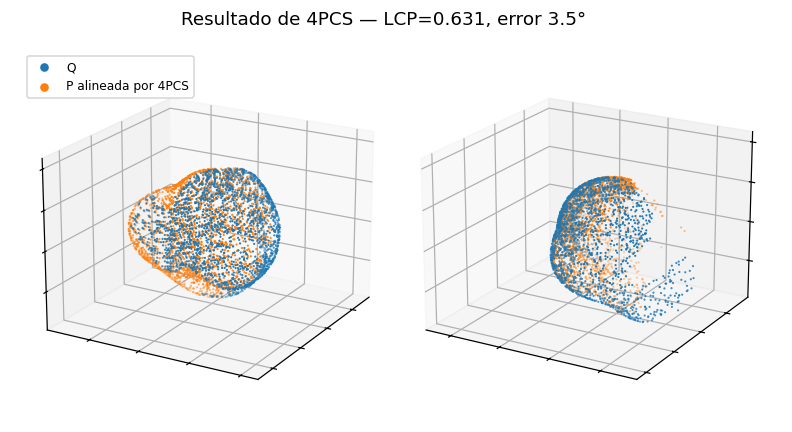

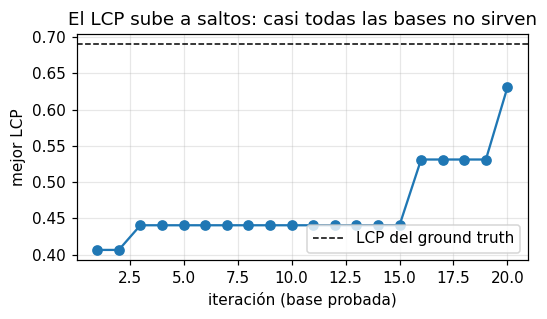

In [ ]:
show_clouds([Q, apply_T(T_4pcs, P)], labels=["Q", "P alineada por 4PCS"],
            title=f"Resultado de 4PCS — LCP={score:.3f}, error {ang:.1f}°")

plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, len(hist)+1), hist, "o-")
plt.axhline(s_gt, ls="--", c="k", lw=1, label="LCP del ground truth")
plt.xlabel("iteración (base probada)"); plt.ylabel("mejor LCP"); plt.legend()
plt.title("El LCP sube a saltos: casi todas las bases no sirven"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 4PCS entrega la pose; ICP la termina

El error angular de 4PCS es de unos pocos grados: es una pose **gruesa**, y esa era
exactamente la promesa del paper — *"entrega una pose que después ICP refina en dos o tres
iteraciones"*. Ejecuta la celda siguiente para ver el refinamiento.

4PCS      :   3.47°   traslación 0.0298
4PCS + ICP:   0.41°   traslación 0.0026


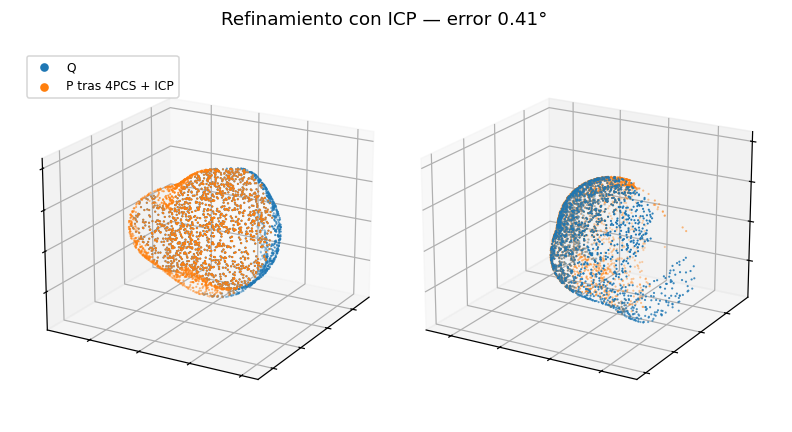

In [ ]:
# @title ICP punto-a-punto (dado) — el refinamiento final
def icp(P, Q, T0, delta, iters=30, tol=1e-7):
    """ICP con rechazo de correspondencias a más de 3δ. Refina T0."""
    tree = cKDTree(Q); T = T0.copy(); prev = np.inf
    for _ in range(iters):
        X = apply_T(T, P)
        d, j = tree.query(X, k=1)
        m = d <= 3*delta
        if m.sum() < 10: break
        T = kabsch(X[m], Q[j[m]]) @ T
        e = d[m].mean()
        if abs(prev - e) < tol: break
        prev = e
    return T

T_icp = icp(P, Q, T_4pcs, DELTA)
a2, t2 = rot_trans_error(T_icp, T_GT, DIAG)
print(f"4PCS      : {ang:6.2f}°   traslación {tra:.4f}")
print(f"4PCS + ICP: {a2:6.2f}°   traslación {t2:.4f}")
show_clouds([Q, apply_T(T_icp, P)], labels=["Q", "P tras 4PCS + ICP"],
            title=f"Refinamiento con ICP — error {a2:.2f}°")

---
## 1.6 Aceleración con normales, y el régimen para el que 4PCS fue diseñado

### Normales: el descriptor más pobre posible, y aun así sirve

4PCS **no necesita** descriptores, pero **se beneficia** de ellos cuando existen. El paper
muestra que incluso la normal de superficie —que ni siquiera es invariante rígida— ya da un
factor 2. El truco es usar una cantidad que **sí** sea invariante rígida: el **ángulo entre
las rectas normales** de dos puntos,

$$N(x,y) \;=\; \angle\bigl(\ell_{N_x},\, \ell_{N_y}\bigr) \;=\; \arccos\bigl|\,n_x\cdot n_y\,\bigr|.$$

El valor absoluto es la clave: es un ángulo entre **rectas**, no entre vectores orientados, así
que **no requiere consistencia global de la orientación de las normales** — y orientar normales
globalmente en un escaneo crudo es un problema en sí mismo. Filtro sobre los pares:

$$\{q_1,q_2\}\ \text{sobrevive}\iff \|q_1-q_2\|\approx d_1 \ \wedge\ N(q_1,q_2)\approx N(a,b)
\quad(\text{y análogo para } d_2, N(c,d)).$$

### Ejercicio 6 (8 min) — el filtro por ángulo entre normales

Implementa `angulo_entre_rectas` y `filtro_normales`, y mide cuánto reducen $|U|$.

In [ ]:
def angulo_entre_rectas(n1, n2):
    n1 = np.atleast_2d(n1); n2 = np.atleast_2d(n2)
    c = np.clip(np.abs(np.sum(n1*n2, axis=1)), 0.0, 1.0)
    return np.degrees(np.arccos(c))

def filtro_normales(pairs, N, ang_ref, tol):
    ang = angulo_entre_rectas(N[pairs[:, 0]], N[pairs[:, 1]])
    return np.abs(ang - ang_ref) < tol
print("angulo_entre_rectas y filtro_normales redefinidas")

angulo_entre_rectas y filtro_normales redefinidas


In [ ]:
# --- Test del Ejercicio 6 ---------------------------------------------------
assert abs(angulo_entre_rectas(np.array([1., 0, 0]), np.array([0., 1, 0]))[0] - 90) < 1e-9
assert abs(angulo_entre_rectas(np.array([1., 0, 0]), np.array([-1., 0, 0]))[0]) < 1e-3, \
       "el ángulo entre RECTAS ignora el signo: 0 grados, no 180"
_a = angulo_entre_rectas(np.array([[1., 0, 0], [1., 1, 0]/np.sqrt(2)]),
                         np.array([[1., 1, 0]/np.sqrt(2)]*2))
assert np.allclose(_a, [45., 0.], atol=1e-3)
assert filtro_normales(np.array([[0, 1]]), np.array([[1., 0, 0], [0., 1, 0]]), 90.0, 5.0)[0]
assert not filtro_normales(np.array([[0, 1]]), np.array([[1., 0, 0], [0., 1, 0]]), 10.0, 5.0)[0]

# ¿cuánto poda el filtro sobre el par de escaneos real?
rng_t = np.random.default_rng(0)
Pr = P[rng_t.choice(len(P), 400, replace=False)]
Qr = Q[rng_t.choice(len(Q), 400, replace=False)]
NPr, NQr = estimate_normals(Pr), estimate_normals(Qr)
Dr = np.linalg.norm(Qr[:, None, :]-Qr[None, :, :], axis=-1)

tot, tot_f = 0, 0
for _ in range(5):
    sel = select_coplanar_base(Pr, 0.60, DELTA, rng_t, diag=DIAG)
    if sel is None: continue
    idx, r1, r2 = sel; B = Pr[idx]
    d1, d2 = np.linalg.norm(B[0]-B[1]), np.linalg.norm(B[2]-B[3])
    R1 = pairs_at_distance(Qr, d1, DELTA, Dr)
    R2 = pairs_at_distance(Qr, d2, DELTA, Dr)
    m1 = filtro_normales(R1, NQr, angulo_entre_rectas(NPr[idx[0]], NPr[idx[1]])[0], 25.)
    m2 = filtro_normales(R2, NQr, angulo_entre_rectas(NPr[idx[2]], NPr[idx[3]])[0], 25.)
    tot   += len(R1) + len(R2)
    tot_f += int(m1.sum()) + int(m2.sum())
    print(f"  base: |R1| {len(R1):5d} -> {int(m1.sum()):5d}    |R2| {len(R2):5d} -> {int(m2.sum()):5d}")

assert tot_f < 0.95*tot, "el filtro debería podar una fracción apreciable de los pares"
print(f"\nOK — el filtro deja el {100*tot_f/tot:.0f} % de los pares candidatos.")
print("Menos pares => menos puntos intermedios => menos conjuntos congruentes que verificar.")

  base: |R1|  2807 ->  1896    |R2|  4661 ->  4141
  base: |R1|  4140 ->  3169    |R2|  1163 ->   721
  base: |R1|  1719 ->   816    |R2|  2126 ->  2009
  base: |R1|  3919 ->  2961    |R2|  3487 ->  3161
  base: |R1|  3340 ->  3005    |R2|  3691 ->  3258

OK — el filtro deja el 81 % de los pares candidatos.
Menos pares => menos puntos intermedios => menos conjuntos congruentes que verificar.


In [ ]:
# @title 4PCS con el filtro de normales activado (ejecutar) — medimos la aceleración real
def fourpcs_normales(P, Q, delta, f=0.5, ps=0.99, seed=0, n_sample=400, n_verify=150,
                     angle_tol=20.0, max_iters=None, verbose=False):
    rng = np.random.default_rng(seed)
    Pr = P[rng.choice(len(P), min(n_sample, len(P)), replace=False)]
    Qr = Q[rng.choice(len(Q), min(n_sample, len(Q)), replace=False)]
    NPr, NQr = estimate_normals(Pr), estimate_normals(Qr)
    tree_Q, tree_P = cKDTree(Q), cKDTree(Pr)
    diag = float(np.linalg.norm(P.max(0)-P.min(0)))
    D = np.linalg.norm(Qr[:, None, :]-Qr[None, :, :], axis=-1)
    L = n_bases_needed(f, 4, ps)
    if max_iters: L = min(L, max_iters)
    best_T, best_s, hist = np.eye(4), -1.0, []
    for it in range(L):
        sel = select_coplanar_base(Pr, f, delta, rng, tree=tree_P, diag=diag)
        if sel is None:
            hist.append(best_s); continue
        idx, r1, r2 = sel; B = Pr[idx]
        d1, d2 = np.linalg.norm(B[0]-B[1]), np.linalg.norm(B[2]-B[3])
        R1 = pairs_at_distance(Qr, d1, delta, D); R2 = pairs_at_distance(Qr, d2, delta, D)
        if len(R1) == 0 or len(R2) == 0:
            hist.append(best_s); continue
        R1 = R1[filtro_normales(R1, NQr, angulo_entre_rectas(NPr[idx[0]], NPr[idx[1]])[0], angle_tol)]
        R2 = R2[filtro_normales(R2, NQr, angulo_entre_rectas(NPr[idx[2]], NPr[idx[3]])[0], angle_tol)]
        if len(R1) == 0 or len(R2) == 0:
            hist.append(best_s); continue
        ij1 = np.vstack([R1, R1[:, ::-1]]); e1 = Qr[ij1[:, 0]] + r1*(Qr[ij1[:, 1]]-Qr[ij1[:, 0]])
        ij2 = np.vstack([R2, R2[:, ::-1]]); e2 = Qr[ij2[:, 0]] + r2*(Qr[ij2[:, 1]]-Qr[ij2[:, 0]])
        hits = cKDTree(e1).query_ball_point(e2, delta*(1+2*max(r1, r2)))
        lens = np.fromiter((len(h) for h in hits), int, len(hits))
        if lens.sum() == 0:
            hist.append(best_s); continue
        m_idx = np.repeat(np.arange(len(hits)), lens)
        h_idx = np.concatenate([np.asarray(h, int) for h in hits if len(h)])
        q = np.stack([ij1[h_idx, 0], ij1[h_idx, 1], ij2[m_idx, 0], ij2[m_idx, 1]], 1)
        q = q[(q[:, 0] != q[:, 2]) & (q[:, 0] != q[:, 3]) &
              (q[:, 1] != q[:, 2]) & (q[:, 1] != q[:, 3])]
        cruz = [(0, 2), (0, 3), (1, 2), (1, 3)]
        ref = np.array([np.linalg.norm(B[i]-B[j]) for i, j in cruz])
        if len(q):
            Uq = Qr[q]
            cur = np.stack([np.linalg.norm(Uq[:, i]-Uq[:, j], axis=1) for i, j in cruz], 1)
            q = q[np.all(np.abs(cur-ref) <= 2*delta, 1)]
        for qq in q:
            T = kabsch(B, Qr[qq])
            if lcp(T, P, tree_Q, delta, sample=n_verify, rng=rng) > best_s:
                s = lcp(T, P, tree_Q, delta)
                if s > best_s: best_s, best_T = s, T
        hist.append(best_s)
        if verbose: print(f"  iter {it+1}: |U|={len(q)}  LCP={best_s:.3f}")
        if best_s >= f: break
    return best_T, float(best_s), hist

t0 = time.time()
T_n, s_n, h_n = fourpcs_normales(P, Q, DELTA, f=0.60, seed=0, angle_tol=20.0)
dt_n = time.time() - t0
a_n, t_n_ = rot_trans_error(T_n, T_GT, DIAG)
print(f"sin normales : {dt:6.1f} s   LCP={score:.3f}   error {ang:.2f}°   ({len(hist)} iters)")
print(f"con normales : {dt_n:6.1f} s   LCP={s_n:.3f}   error {a_n:.2f}°   ({len(h_n)} iters)")
print(f"\naceleración: {dt/max(dt_n,1e-9):.1f}x")

sin normales :  115.8 s   LCP=0.631   error 3.47°   (20 iters)
con normales :   16.1 s   LCP=0.601   error 6.35°   (3 iters)

aceleración: 7.2x


> El paper reporta ×2 con normales (Tabla 1: la jarra de agua pasa de 159.5 s a 78.4 s;
> Jerusalén de 6.4 s a 1.1 s). En datos muy ruidosos hay que usar un umbral de ángulo alto
> —las normales no son confiables— y por eso la ganancia se queda ahí.
>
> **Conexión con Super4PCS.** Mellado, Aiger & Mitra (2014) llevan esta idea más lejos:
> indexan los pares por su orientación en la **esfera de Gauss** y, sobre todo, reemplazan la
> extracción $O(n^2)$ de pares por una **cáscara esférica rasterizada** en una rejilla, con lo
> que el costo pasa a $O(n+k_1+k_2)$ por iteración. En una implementación desde cero la
> ganancia real está concentrada exactamente ahí: ×1.3 a $n=500$, ×11 a $n=4000$.

---

### El régimen para el que 4PCS fue diseñado

El par de escaneos con el que trabajamos tiene relieve: los descriptores locales también
funcionarían. Probemos ahora el caso que motivó el paper — un **escaneo aéreo estilizado**:
suelo plano y bloques rectangulares. Superficies planas, sin nada distintivo que describir.

|P|=2775  |Q|=2880  LCP del ground truth = 0.636


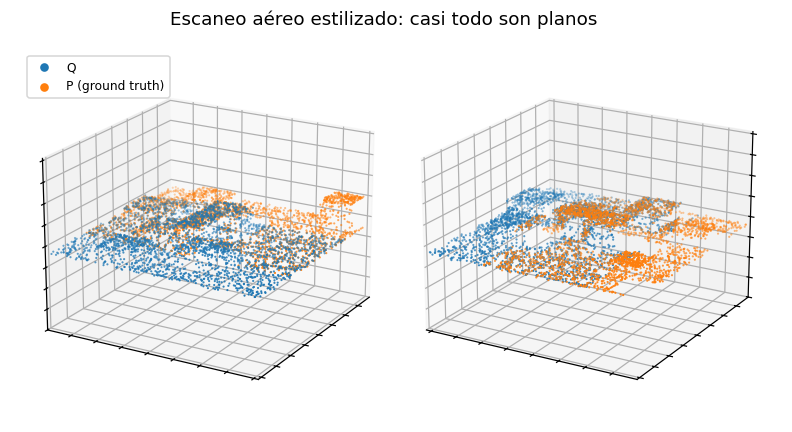


4 iteraciones, 29 s   LCP=0.574
4PCS      :  2.77°  traslación 0.0815
4PCS + ICP:  2.80°  traslación 0.0802


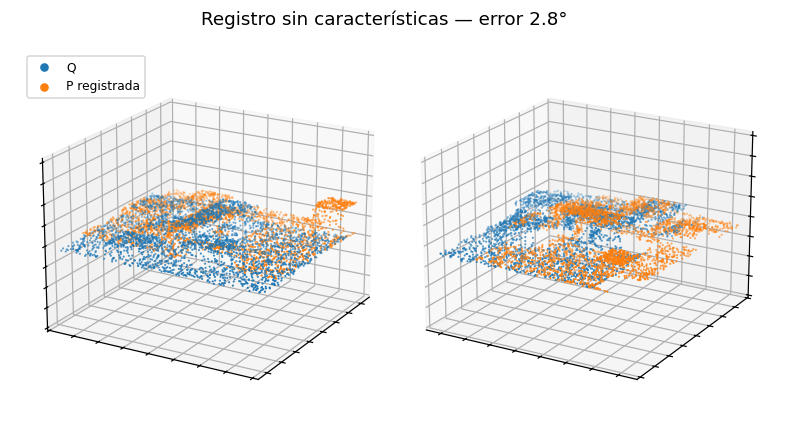

In [ ]:
CITY = city_cloud(6000)
Pc, Qc, Tc_gt = make_scan_pair2(CITY, dphi_deg=45.0, crop=0.35, noise=0.002, seed=2)
DIAG_c  = float(np.linalg.norm(Qc.max(0)-Qc.min(0)))
DELTA_c = 0.020*DIAG_c
print(f"|P|={len(Pc)}  |Q|={len(Qc)}  LCP del ground truth = "
      f"{lcp(Tc_gt, Pc, cKDTree(Qc), DELTA_c):.3f}")
show_clouds([Qc, apply_T(Tc_gt, Pc)], labels=["Q", "P (ground truth)"],
            title="Escaneo aéreo estilizado: casi todo son planos")

t0 = time.time()
Tc, sc, hc = fourpcs(Pc, Qc, DELTA_c, f=0.55, seed=0, n_sample=450)
Tc_icp = icp(Pc, Qc, Tc, DELTA_c)
ac, tc = rot_trans_error(Tc, Tc_gt, DIAG_c)
ac2, tc2 = rot_trans_error(Tc_icp, Tc_gt, DIAG_c)
print(f"\n{len(hc)} iteraciones, {time.time()-t0:.0f} s   LCP={sc:.3f}")
print(f"4PCS      : {ac:5.2f}°  traslación {tc:.4f}")
print(f"4PCS + ICP: {ac2:5.2f}°  traslación {tc2:.4f}")
show_clouds([Qc, apply_T(Tc_icp, Pc)], labels=["Q", "P registrada"],
            title=f"Registro sin características — error {ac2:.1f}°")

### Discusión: por qué el error residual no baja de ahí

Fíjate en que el error de **traslación** se queda relativamente alto aunque la rotación sea
buena. La razón es la **limitación 1** que declaran los autores: un objeto ***slippable***
—uno que admite un movimiento rígido que lo deja (casi) invariante— no está determinado por
sus posiciones. Aquí, el suelo es un plano grande: deslizarlo sobre sí mismo no cambia el LCP.
Lo único que fija la solución en esas direcciones son los bloques. **No es un defecto del
algoritmo sino del planteamiento: la información no está en los puntos.** Un pipeline con
descriptores sufre exactamente lo mismo, y por la misma razón.

### Las limitaciones, según los propios autores

1. **Objetos *slippable***: solución subóptima en la dirección del deslizamiento. Requiere
   información semántica, no geométrica.
2. **Solapamiento extremadamente bajo**: no cabe una base ancha dentro del solapamiento, y hay
   que sacrificar estabilidad. (Aunque cualquier método sufre en ese régimen.)
3. **La versión afín no escala**: pierde el espacio lineal, vuelve a $O(n^2)$ de memoria.
4. **Redundante en datos limpios.** La más honesta y la menos citada: *si el dato es limpio y
   los descriptores se pueden calcular de forma confiable, hay maneras más simples y rápidas de
   registrar.* **4PCS es la herramienta del régimen difícil, no la herramienta por defecto.**

Y dos que el paper no declara: la extracción de pares cuesta $O(n^2)$ aunque la salida sea
$O(n)$ (el blanco de Super4PCS), y la sensibilidad a $\delta$, heredada de todo esquema de
consenso.

> **Para probar por tu cuenta** (fuera del tiempo del tutorial): repite el registro con
> `make_scan_pair(SHAPE, dphi_deg=90)` (solapamiento ~45 %), con `noise=0.005` y con
> `outlier_frac=0.20`. Con 20 % de outliers 4PCS sigue entregando una pose usable: los outliers
> simplemente no suman al LCP. Ese es todo el argumento del paper contra el pre-filtrado.

---
# Parte II — RANSAC para ajuste de primitivas

## 2.1 El mismo estimador, otro problema

Cambiamos de problema pero no de idea. Ahora la entrada es **una sola** nube —el escaneo de
una pieza mecánica, un edificio, una escena de interior— y queremos descomponerla en
**primitivas geométricas**: planos, esferas, cilindros, conos, toros. Es la base del *reverse
engineering* de modelos CAD y de la simplificación de escaneos (Schnabel, Wahl & Klein 2007).

La estructura del algoritmo es idéntica a la de 4PCS:

| | 4PCS | RANSAC de primitivas |
|---|---|---|
| Muestra mínima | base de 4 puntos coplanares | 3 puntos (plano), 4 (esfera), 2 con normales (cilindro) |
| Hipótesis | $T \in SE(3)$ | parámetros de la primitiva |
| Puntuación | $\mathrm{LCP}_\delta$: puntos de $P$ a $\le\delta$ de $Q$ | consenso: puntos a $\le\varepsilon$ de la superficie |
| Iteraciones | Ec. 1 con $N=4$, $p_g=f$ | Ec. 1 con $N=k$, $p_g=w$ |
| Robustez | outliers suman 0 | outliers suman 0 |

La misma fórmula gobierna las dos:

$$L \;>\; \frac{\log(1-p_s)}{\log\!\left(1-w^{\,k}\right)}$$

donde ahora $w$ es la fracción de *inliers* de la primitiva que buscamos y $k$ el tamaño de la
muestra mínima. Dos consecuencias prácticas:

* **$k$ importa exponencialmente.** Por eso el cilindro se ajusta con **2 puntos y sus
  normales** en vez de con 5 puntos: bajar $k$ de 5 a 2 con $w=0.2$ lleva $L$ de ~14 000 a ~114.
  Es la misma economía por la que 4PCS prefiere una base coplanar "especial".
* **$w$ se puede estimar sobre la marcha.** Cada vez que encontramos un consenso mejor,
  actualizamos $w \leftarrow c_\text{best}/n$ y recalculamos $L$. Es el **RANSAC adaptativo**.

### Ejercicio 7 (8 min) — el presupuesto de iteraciones

In [ ]:
def n_iters(w, k, ps=0.99):
    w = float(np.clip(w, 1e-6, 0.999))
    return int(np.ceil(np.log(1-ps)/np.log(1 - w**k)))
print("n_iters redefinida")

n_iters redefinida


In [ ]:
# --- Test del Ejercicio 7 ---------------------------------------------------
assert n_iters(0.5, 3) == 35 and n_iters(0.5, 4) == 72
assert n_iters(0.99, 3) <= 4

print("   w   | plano k=3 | esfera k=4 | cilindro 5 pts (k=5) | cilindro 2 pts+normales (k=2)")
print("-------|-----------|------------|----------------------|------------------------------")
for w in [0.6, 0.4, 0.2, 0.1, 0.05]:
    print(f"  {w:.2f} | {n_iters(w,3):9d} | {n_iters(w,4):10d} | {n_iters(w,5):20d} |"
          f" {n_iters(w,2):28d}")
assert n_iters(0.2, 5) > 50*n_iters(0.2, 2)
print("\nOK — bajar k de 5 a 2 usando las normales ahorra dos órdenes de magnitud.")
print("Es exactamente el mismo argumento por el que 4PCS elige una base 'especial'.")

   w   | plano k=3 | esfera k=4 | cilindro 5 pts (k=5) | cilindro 2 pts+normales (k=2)
-------|-----------|------------|----------------------|------------------------------
  0.60 |        19 |         34 |                   57 |                           11
  0.40 |        70 |        178 |                  448 |                           27
  0.20 |       574 |       2876 |                14389 |                          113
  0.10 |      4603 |      46050 |               460515 |                          459
  0.05 |     36840 |     736825 |             14736543 |                         1840

OK — bajar k de 5 a 2 usando las normales ahorra dos órdenes de magnitud.
Es exactamente el mismo argumento por el que 4PCS elige una base 'especial'.


---
## 2.2 La escena de trabajo y el ajuste de un plano

Generamos una escena sintética con un **plano**, una **esfera** y un **cilindro**, más ruido
gaussiano y un 5 % de outliers uniformes. Las normales se estiman por PCA local — sin
orientación consistente, igual que en un escaneo real.

6300 puntos:  plano 2000,  esfera 2000,  cilindro 2000,  outliers 300


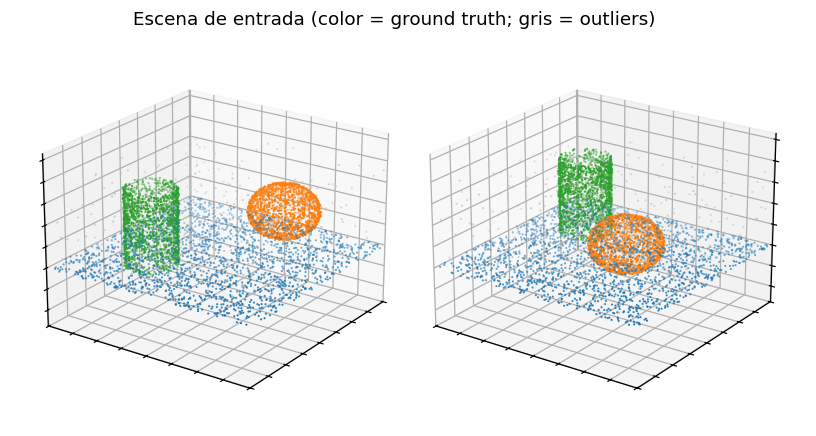

In [ ]:
# @title 2.2.1 — Escena sintética con primitivas (ejecutar)
def make_primitive_scene(n=6000, noise=0.004, outlier_frac=0.05, seed=0):
    """Devuelve (X, lab) con lab: 0=plano, 1=esfera, 2=cilindro, -1=outlier."""
    rng = np.random.default_rng(seed); k = n//3
    plano = np.stack([rng.uniform(-1, 1, k), rng.uniform(-1, 1, k), np.zeros(k)], 1)
    v = rng.normal(size=(k, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True)
    esfera = np.array([-.45, .35, .45]) + 0.30*v
    th, h = rng.uniform(0, 2*np.pi, k), rng.uniform(0, .9, k)
    cil = np.array([.45, -.35, 0.]) + np.stack([.22*np.cos(th), .22*np.sin(th), h], 1)
    X = np.vstack([plano, esfera, cil])
    lab = np.concatenate([np.zeros(k, int), np.ones(k, int), 2*np.ones(k, int)])
    X = X + noise*rng.normal(size=X.shape)
    if outlier_frac > 0:
        m = int(outlier_frac*n)
        O = np.stack([rng.uniform(-1, 1, m), rng.uniform(-1, 1, m), rng.uniform(0, 1, m)], 1)
        X = np.vstack([X, O]); lab = np.concatenate([lab, -np.ones(m, int)])
    p = rng.permutation(len(X))
    return X[p], lab[p]

XS, LAB = make_primitive_scene(6000, noise=0.004, outlier_frac=0.05, seed=0)
NS = estimate_normals(XS, k=25)
EPS = 0.012                                   # tolerancia de inlier
print(f"{len(XS)} puntos:  plano {int((LAB==0).sum())},  esfera {int((LAB==1).sum())},  "
      f"cilindro {int((LAB==2).sum())},  outliers {int((LAB==-1).sum())}")
show_segmentation(XS, LAB, "Escena de entrada (color = ground truth; gris = outliers)")

### Ejercicio 8 (10 min) — plano

Un plano se ajusta con **3 puntos**: $n = \dfrac{(p_1-p_0)\times(p_2-p_0)}{\|\cdot\|}$, y la
distancia de un punto $x$ al plano es $|\,n\cdot(x-p_0)\,|$.

Implementa además `normales_plano`: la **normal teórica de la primitiva** en cada punto. La
usaremos en §2.4 para el *test de normales*, que es lo que separa un buen ajuste de primitivas
de uno malo.

Devuelve `None` si los 3 puntos son (casi) colineales — una degeneración que hay que
detectar, no ignorar.

In [ ]:
def fit_plano(pts, nrm=None):
    p0 = pts[0]
    n = np.cross(pts[1]-p0, pts[2]-p0)
    ln = np.linalg.norm(n)
    if ln < 1e-12:
        return None
    return ("plane", p0, n/ln)

def dist_plano(model, X):
    _, p0, n = model
    return np.abs((X - p0) @ n)

def normales_plano(model, X):
    _, p0, n = model
    return np.tile(n, (len(X), 1))
print("plano redefinido")

plano redefinido


In [ ]:
# --- Test del Ejercicio 8 ---------------------------------------------------
m = fit_plano(np.array([[0., 0, 1], [1., 0, 1], [0., 1, 1]]))
assert m is not None and m[0] == "plane"
assert abs(abs(m[2] @ np.array([0., 0, 1])) - 1) < 1e-9, "la normal debería ser +-z"
assert abs(np.linalg.norm(m[2]) - 1) < 1e-12, "la normal debe ser unitaria"
assert np.allclose(dist_plano(m, np.array([[5., 7, 1.3], [0., 0, 1]])), [0.3, 0.0])
assert normales_plano(m, np.zeros((4, 3))).shape == (4, 3)
assert fit_plano(np.array([[0., 0, 0], [1., 0, 0], [2., 0, 0]])) is None, \
       "3 puntos colineales no definen un plano"

# sobre la escena real: ¿cuántos puntos del plano recupera un ajuste con 3 inliers?
idx = np.nonzero(LAB == 0)[0][:3]
mp = fit_plano(XS[idx])
inl = dist_plano(mp, XS) <= EPS
print(f"OK — con 3 puntos del plano se recuperan {int(inl.sum())} inliers "
      f"({int((LAB[inl]==0).sum())} son realmente del plano).")

OK — con 3 puntos del plano se recuperan 1888 inliers (1846 son realmente del plano).


---
## 2.3 Esfera y cilindro

**Esfera (4 puntos).** El centro equidista de los cuatro:
$\|x-c\|^2 = \|x_0-c\|^2$ para $x\in\{x_1,x_2,x_3\}$. Desarrollando, los términos cuadráticos
en $c$ se cancelan y queda un sistema **lineal** $3\times3$:
$$2(x_i - x_0)^\top c \;=\; \|x_i\|^2 - \|x_0\|^2,\qquad i=1,2,3.$$
Te la damos hecha.

**Cilindro (2 puntos + sus normales).** Aquí está la idea que hace práctico el método:

* En un cilindro, **todas las normales son perpendiculares al eje**. Con dos normales
  $n_1, n_2$ el eje es $a = \dfrac{n_1\times n_2}{\|n_1\times n_2\|}$.
* Proyectamos todo al plano perpendicular a $a$: el cilindro se convierte en una
  **circunferencia** y las normales en radios.
* En 2D, el centro es la **intersección de las dos rectas normales**; el radio, la distancia
  del centro a cualquiera de los dos puntos.

Es decir: usando la información de primer orden (las normales) el tamaño de la muestra mínima
baja de 5 a 2, y con ella el presupuesto $L$ baja dos órdenes de magnitud (Ejercicio 7).

### Ejercicio 9 (14 min) — cilindro desde 2 puntos y sus normales

In [ ]:
# @title `fit_esfera`, `dist_esfera`, `normales_esfera` (dadas — ejecutar)
def fit_esfera(pts, nrm=None):
    """pts: (4,3). Sistema lineal 3x3 para el centro."""
    A = 2*(pts[1:] - pts[0])
    b = (pts[1:]**2).sum(1) - (pts[0]**2).sum()
    try:
        c = np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        return None                                   # 4 puntos coplanares
    r = float(np.linalg.norm(pts[0] - c))
    return None if (not np.isfinite(r) or r <= 0) else ("sphere", c, r)

def dist_esfera(model, X):
    _, c, r = model
    return np.abs(np.linalg.norm(X - c, axis=1) - r)

def normales_esfera(model, X):
    _, c, r = model
    v = X - c
    return v/np.maximum(np.linalg.norm(v, axis=1, keepdims=True), 1e-12)

print("listo")

listo


In [ ]:
def fit_cilindro(pts, nrm):
    a = np.cross(nrm[0], nrm[1]); la = np.linalg.norm(a)
    if la < 1e-6:
        return None                       # normales paralelas: eje indeterminado
    a = a/la
    u = np.cross(a, [1., 0., 0.])
    if np.linalg.norm(u) < 1e-6: u = np.cross(a, [0., 1., 0.])
    u /= np.linalg.norm(u); v = np.cross(a, u)
    P2 = np.stack([pts @ u, pts @ v], 1)
    N2 = np.stack([nrm @ u, nrm @ v], 1)
    ln = np.linalg.norm(N2, axis=1)
    if np.any(ln < 1e-6):
        return None
    N2 = N2/ln[:, None]
    M = np.stack([N2[0], -N2[1]], 1)      # [s, t] tal que P2[0]+s*N2[0] = P2[1]+t*N2[1]
    if abs(np.linalg.det(M)) < 1e-9:
        return None
    st = np.linalg.solve(M, P2[1] - P2[0])
    c2 = P2[0] + st[0]*N2[0]
    r = float(np.linalg.norm(c2 - P2[0]))
    if not np.isfinite(r) or r <= 0:
        return None
    return ("cylinder", c2[0]*u + c2[1]*v, a, r)

def dist_cilindro(model, X):
    _, c, a, r = model
    d = X - c
    d = d - np.outer(d @ a, a)            # componente perpendicular al eje
    return np.abs(np.linalg.norm(d, axis=1) - r)

def normales_cilindro(model, X):
    _, c, a, r = model
    d = X - c
    d = d - np.outer(d @ a, a)
    return d/np.maximum(np.linalg.norm(d, axis=1, keepdims=True), 1e-12)
print("cilindro redefinido")

cilindro redefinido


In [ ]:
# --- Test del Ejercicio 9 ---------------------------------------------------
# cilindro sintético exacto: eje z, centro (1,2), radio 0.5
ax = np.array([0., 0., 1.]); ctr = np.array([1., 2., 0.]); rad = 0.5
th = np.array([0.3, 2.1])
pts = ctr + np.stack([rad*np.cos(th), rad*np.sin(th), np.array([0.4, -1.7])], 1)
nrm = np.stack([np.cos(th), np.sin(th), np.zeros(2)], 1)

m = fit_cilindro(pts, nrm)
assert m is not None and m[0] == "cylinder"
assert abs(abs(m[2] @ ax) - 1) < 1e-9,              f"eje mal estimado: {m[2]}"
assert abs(m[3] - rad) < 1e-9,                      f"radio mal estimado: {m[3]}"
d_eje = np.linalg.norm(np.cross(m[1]-ctr, ax))
assert d_eje < 1e-9,                                f"el eje no pasa por el centro: {d_eje}"
assert abs(fit_cilindro(pts, -nrm)[3] - rad) < 1e-9, "debe funcionar con normales invertidas"

# distancias
Xt = np.array([[1., 2., 5.], [1.+0.5, 2., -3.], [1.+0.8, 2., 0.]])
assert np.allclose(dist_cilindro(m, Xt), [0.5, 0.0, 0.3], atol=1e-9)
assert fit_cilindro(pts, np.array([[1., 0, 0], [1., 0, 0]])) is None, \
       "normales paralelas: el eje es indeterminado"
print(f"OK — eje {np.round(np.abs(m[2]),4)}, radio {m[3]:.4f} (verdadero {rad})")

OK — eje [0. 0. 1.], radio 0.5000 (verdadero 0.5)


---
## 2.4 El motor RANSAC, las degeneraciones y la extracción secuencial

Ya tenemos los tres modelos. Falta el motor, y con él los dos ingredientes que separan un
ajuste de primitivas que funciona de uno que no:

**(1) El test de normales.** Contar solo por distancia es insuficiente: una esfera de radio
enorme aproxima un plano, un cilindro de radio enorme también. Schnabel et al. exigen que la
normal estimada del dato y la **normal teórica de la primitiva** coincidan dentro de un
umbral $\alpha$. Es el mismo truco del ángulo diedro de §1.6: información de primer orden que
descarta hipótesis que la distancia sola no distingue.

**(2) Cotas de escala.** Aun con test de normales, conviene acotar el radio: una esfera de
radio 300 en una escena de tamaño 1 no es una esfera, es un plano disfrazado. Lo verás medido
en el experimento de más abajo.

Y una tercera idea que **no** implementaremos pero conviene conocer, porque es la contribución
central de Schnabel et al. 2007: el **muestreo localizado**. Muestrear $k$ puntos
uniformemente de toda la nube es malísimo cuando hay muchas primitivas — la probabilidad de que
los $k$ caigan en la *misma* primitiva es baja. Ellos muestrean el primer punto al azar y los
demás **en su vecindad** (usando un octree de varios niveles), lo que aumenta $w$
enormemente. Además puntúan cada hipótesis por su **componente conexa** más grande, no por el
total de inliers: eso evita que un plano "coseche" puntos coplanares de otras partes de la
escena.

### Ejercicio 10 (12 min) — el motor, con y sin las salvaguardas

In [ ]:
# @title Registro de primitivas (ejecutar)
PRIMITIVAS = {
    "plane":    dict(k=3, fit=lambda p, n: fit_plano(p),  dist=dist_plano,
                     nrm=normales_plano,    color="tab:blue"),
    "sphere":   dict(k=4, fit=lambda p, n: fit_esfera(p), dist=dist_esfera,
                     nrm=normales_esfera,   color="tab:orange"),
    "cylinder": dict(k=2, fit=fit_cilindro,               dist=dist_cilindro,
                     nrm=normales_cilindro, color="tab:green"),
}
print("listo")

listo


In [ ]:
def ransac_primitiva(X, N, kind, thresh, iters=2000, angle_tol=None, max_radius=None,
                     seed=0, mask=None, adaptive=True, ps=0.99):
    rng  = np.random.default_rng(seed)
    spec = PRIMITIVAS[kind]; k = spec["k"]
    pool = np.arange(len(X)) if mask is None else np.nonzero(mask)[0]
    if len(pool) < k:
        return None, np.zeros(len(X), bool), 0
    best_m, best_inl, best_c, it, budget = None, np.zeros(len(X), bool), 0, 0, iters
    while it < budget:
        it += 1
        s = rng.choice(pool, k, replace=False)
        m = spec["fit"](X[s], N[s])
        if m is None:
            continue
        if max_radius is not None and kind in ("sphere", "cylinder") and m[-1] > max_radius:
            continue
        inl = spec["dist"](m, X) <= thresh
        if angle_tol is not None:
            inl &= angulo_entre_rectas(spec["nrm"](m, X), N) <= angle_tol
        if mask is not None:
            inl = inl & mask
        c = int(inl.sum())
        if c > best_c:
            best_c, best_inl, best_m = c, inl, m
            if adaptive:
                budget = min(budget, max(it + 10, n_iters(best_c/len(pool), k, ps)))
    return best_m, best_inl, it
print("ransac_primitiva redefinida")

ransac_primitiva redefinida


In [ ]:
# --- Test del Ejercicio 10 --------------------------------------------------
res = {}
for kind in ("plane", "sphere", "cylinder"):
    for guard in (False, True):
        m, inl, it = ransac_primitiva(
            XS, NS, kind, EPS, iters=4000, seed=0,
            angle_tol=(20.0 if guard else None),
            max_radius=(1.0 if guard else None))
        pureza = np.bincount(LAB[inl]+1, minlength=4)   # [-1, 0, 1, 2] = [out, plano, esf, cil]
        dom = int(np.argmax(pureza[1:]))                # etiqueta dominante
        radio = m[-1] if kind != "plane" else float("nan")
        res[(kind, guard)] = (int(inl.sum()), dom, radio, it)
        print(f"{kind:9s} salvaguardas={str(guard):5s}  inliers={int(inl.sum()):5d}  "
              f"radio={radio:8.2f}  etiqueta dominante={dom}  iters={it}")

# sin salvaguardas, la 'esfera' y el 'cilindro' se comen el PLANO (etiqueta 0) con radio enorme
assert res[("sphere", False)][2] > 5,   "sin cota de radio, la esfera debería degenerar en un plano"
assert res[("sphere", False)][1] == 0,  "y sus inliers deberían ser los del plano"
# con salvaguardas, cada primitiva encuentra la suya
assert res[("plane", True)][1] == 0
assert res[("sphere", True)][1] == 1 and res[("sphere", True)][2] < 0.5
assert res[("cylinder", True)][1] == 2 and res[("cylinder", True)][2] < 0.5
assert res[("plane", True)][3] < 4000, "el RANSAC adaptativo debería parar antes del presupuesto"
print("\nOK — sin cota de radio, una esfera de radio ~300 'explica' el plano y gana el consenso.")
print("Ese es el modo de falla clásico del ajuste de primitivas, y no se ve mirando el residuo.")

plane     salvaguardas=False  inliers= 2013  radio=     nan  etiqueta dominante=0  iters=139
plane     salvaguardas=True   inliers= 1935  radio=     nan  etiqueta dominante=0  iters=157
sphere    salvaguardas=False  inliers= 2011  radio=  343.71  etiqueta dominante=0  iters=442
sphere    salvaguardas=True   inliers= 1900  radio=    0.30  etiqueta dominante=1  iters=555
cylinder  salvaguardas=False  inliers= 1667  radio=   26.38  etiqueta dominante=0  iters=64
cylinder  salvaguardas=True   inliers= 1634  radio=    0.22  etiqueta dominante=2  iters=82

OK — sin cota de radio, una esfera de radio ~300 'explica' el plano y gana el consenso.
Ese es el modo de falla clásico del ajuste de primitivas, y no se ve mirando el residuo.


### Extracción secuencial de varias primitivas

El esquema clásico: ajustar la mejor primitiva, **retirar sus inliers**, repetir hasta que el
mejor consenso caiga bajo un mínimo. Es voraz y tiene sus problemas (una primitiva mal ajustada
se lleva puntos que le faltarán a la siguiente), pero es suficiente para ver la idea.

4 primitivas en 10.6 s

  #0 sphere      1980 puntos    99.9 % pertenecen realmente al esfera   radio=0.299
  #1 plane       1948 puntos    99.5 % pertenecen realmente al plano
  #2 cylinder    1422 puntos    99.6 % pertenecen realmente al cilindro   radio=0.228
  #3 cylinder     406 puntos    99.3 % pertenecen realmente al cilindro   radio=0.231

sin asignar: 544 puntos (292 de ellos son outliers reales)


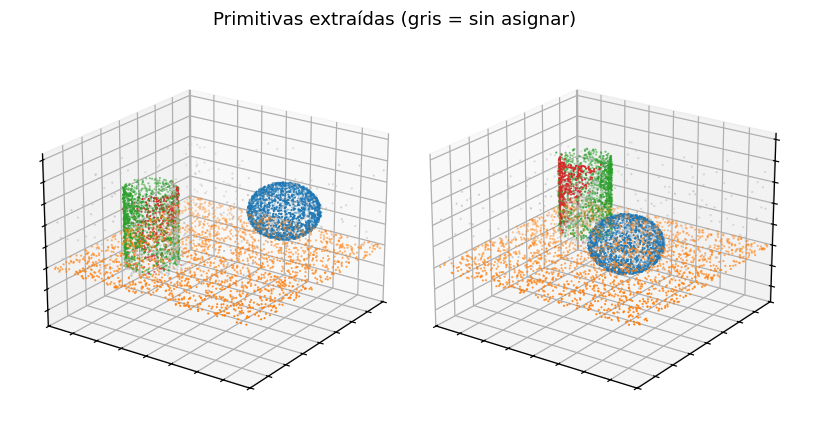

In [ ]:
def extraer_primitivas(X, N, kinds=("plane", "sphere", "cylinder"), thresh=0.012,
                       min_inliers=300, max_prims=5, iters=4000, angle_tol=20.0,
                       max_radius=1.0, seed=0):
    restantes = np.ones(len(X), bool); encontradas = []
    for p in range(max_prims):
        best = None
        for kind in kinds:
            m, inl, _ = ransac_primitiva(X, N, kind, thresh, iters=iters, mask=restantes,
                                         angle_tol=angle_tol, max_radius=max_radius,
                                         seed=seed + 17*p + {"plane": 0, "sphere": 1,
                                                             "cylinder": 2}[kind])
            if m is None: continue
            if best is None or inl.sum() > best[1].sum():
                best = (m, inl, kind)
        if best is None or best[1].sum() < min_inliers:
            break
        m, inl, kind = best
        encontradas.append((kind, m, np.nonzero(inl)[0]))
        restantes &= ~inl
    return encontradas, restantes

t0 = time.time()
prims, restantes = extraer_primitivas(XS, NS, thresh=EPS, min_inliers=300, max_prims=4)
seg = -np.ones(len(XS), int)
print(f"{len(prims)} primitivas en {time.time()-t0:.1f} s\n")
for i, (kind, m, idx) in enumerate(prims):
    seg[idx] = i
    pureza = np.bincount(LAB[idx]+1, minlength=4)
    nombre = {0: "plano", 1: "esfera", 2: "cilindro"}
    dom = int(np.argmax(pureza[1:]))
    print(f"  #{i} {kind:9s}  {len(idx):5d} puntos   "
          f"{100*pureza[1+dom]/len(idx):5.1f} % pertenecen realmente al {nombre[dom]}"
          + (f"   radio={m[-1]:.3f}" if kind != "plane" else ""))
print(f"\nsin asignar: {int(restantes.sum())} puntos "
      f"({int((LAB[restantes]==-1).sum())} de ellos son outliers reales)")
show_segmentation(XS, seg, "Primitivas extraídas (gris = sin asignar)")

**Qué mirar en el resultado.**

* Los outliers uniformes quedan casi todos **sin asignar**: el consenso no los cuenta y no
  penaliza. La misma propiedad que hacía robusto al LCP.
* Los radios recuperados (~0.30 para la esfera, ~0.22 para el cilindro) coinciden con los
  verdaderos: la muestra mínima solo tiene que ser *limpia*, no *precisa*. En una
  implementación seria, después del consenso se **re-ajusta por mínimos cuadrados sobre todos
  los inliers**, igual que ICP refina la pose que entrega 4PCS.
* Es probable que el cilindro aparezca **partido en dos**. Es el defecto conocido del esquema
  voraz, y es justamente lo que Schnabel et al. atacan puntuando por **componente conexa** y
  con muestreo localizado.

### Preguntas rápidas sobre lo que acabas de correr

1. ¿Por qué el test de normales rescata a la esfera pero **no** basta por sí solo? (Pista: en
   una esfera de radio 300, ¿cuánto se parecen sus normales a las de un plano dentro de la
   escena?)
2. Sube `EPS` a `0.05` y vuelve a correr la extracción. ¿Qué le pasa a la pureza? ¿Cuál es el
   equivalente de este parámetro en la Parte I?
3. `n_iters` con $w$ *global* es pesimista cuando la escena tiene muchas primitivas: si el
   plano es solo el 30 % de la nube, ese es el $w$ que hay que usar para *él*, no la fracción
   de inliers de toda la escena. ¿Cómo cambia el argumento con muestreo localizado?

---
# 3. Cierre

## Lo que comparten los dos algoritmos

| | 4PCS | RANSAC de primitivas |
|---|---|---|
| Muestra mínima | 4 puntos coplanares y **anchos** | 3 / 4 / 2 puntos |
| Truco para abaratar la búsqueda | invariantes afines + punto intermedio ⇒ $O(n^2)$ en vez de $O(n^3)$ | normales ⇒ $k$ baja de 5 a 2 |
| Puntuación | $\mathrm{LCP}_\delta$ | consenso |
| Salvaguarda contra hipótesis degeneradas | filtro de congruencia **rígida** (el superconjunto afín es demasiado grande) | test de **normales** y cota de radio |
| Refinamiento posterior | ICP | mínimos cuadrados sobre inliers |
| Parámetro crítico | $\delta$ | $\varepsilon$ |

**La moraleja que hay que quedarse del paper de 4PCS, aunque nunca implementes 4PCS:** puntúa
tus hipótesis por **consenso global**, no por el residuo de las correspondencias que las
generaron. En nuestra evaluación del pipeline con características de esta misma clase,
reemplazar el agrupamiento de Johnson & Hebert por RANSAC **con verificación LCP** subió el
recall de 0.50 a 0.93 — sin tocar ni el detector ni el descriptor.

Y la advertencia honesta, que está en el propio paper (limitación 4): con datos limpios y
descriptores confiables hay maneras más simples y rápidas de registrar. **4PCS es la
herramienta del régimen difícil.**

## Preguntas de discusión

1. ¿Por qué el cuarto punto de la base **no** aporta información para determinar $T$ y sin
   embargo es la clave del algoritmo?
2. Con base de 4 puntos hacen falta más iteraciones que con 3 (tabla del Ejercicio 5). ¿Por qué
   eso no arruina el método?
3. ¿Qué pasa si la base elegida es casi colineal? ¿Y si $r_1 \approx r_2$? (Lo forzamos a mano
   en `select_coplanar_base` — quita esas guardas y observa.)
4. Los invariantes son **afines** pero el problema es **rígido**. ¿Por qué usar la herramienta
   más débil? ¿Qué se paga y dónde se recupera?
5. ¿Por qué el ángulo entre normales **no** requiere orientación consistente de las normales?
6. ¿Por qué el LCP es robusto a outliers y un residuo cuadrático no? Escribe ambos como
   M-estimadores y compara sus funciones de influencia.
7. Un objeto *slippable* rompe a 4PCS. ¿Rompe también a un pipeline con descriptores locales?
8. Super4PCS baja de $O(n^2)$ a $O(n+k)$ solo cambiando **cómo se buscan los pares a distancia
   fija**. ¿Qué supuesto sobre los datos hace posible esa mejora?
9. En la Parte II usamos muestreo uniforme. Con muestreo **localizado** (Schnabel et al.),
   ¿cuál es ahora la interpretación de $w$ en la fórmula de $L$?

## Para seguir

* Aiger, Mitra & Cohen-Or, *4-Points Congruent Sets for Robust Pairwise Surface Registration*,
  ACM TOG 27(3), 2008.
* Mellado, Aiger & Mitra, *Super 4PCS: Fast Global Pointcloud Registration via Smart Indexing*,
  CGF 33(5), 2014.
* Schnabel, Wahl & Klein, *Efficient RANSAC for Point-Cloud Shape Detection*, CGF 26(2), 2007.
* Horn, *Closed-form solution of absolute orientation using unit quaternions*, JOSA A 4(4), 1987.
* Fischler & Bolles, *Random Sample Consensus*, CACM 24(6), 1981.
* Zhou, Park & Koltun, *Fast Global Registration*, ECCV 2016 — y **TEASER++** (Yang et al.
  2020), con garantías de optimalidad certificable.

---
# Soluciones

Celdas plegadas. Ábrelas solo después de intentar el ejercicio; al ejecutarlas se redefine la
función correspondiente y puedes continuar con el resto del notebook.

In [ ]:
# @title Solución — Ejercicio 1: `lcp`
def lcp(T, P, tree_Q, delta, sample=None, rng=None):
    X = P if sample is None else P[rng.choice(len(P), min(sample, len(P)), replace=False)]
    d, _ = tree_Q.query(apply_T(T, X), k=1)
    return float(np.mean(d <= delta))
print("lcp redefinida")

lcp redefinida


In [ ]:
# @title Solución — Ejercicio 2: error angular vs ancho de base
def angular_error_vs_width(widths, eps=0.01, reps=400, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for D in widths:
        errs = []
        for _ in range(reps):
            v = rng.normal(size=(3, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True)
            A = v * (rng.uniform(0, 1, (3, 1))**(1/3)) * (D/2)
            R = random_rotation(rng)
            B = A @ R.T
            Bn = B + eps*rng.normal(size=B.shape)
            Rhat = kabsch(A, Bn)[:3, :3]
            ang = np.degrees(np.arccos(np.clip((np.trace(Rhat @ R.T)-1)/2, -1, 1)))
            errs.append(ang)
        out.append(np.mean(errs))
    return np.array(out)
print("angular_error_vs_width redefinida")

angular_error_vs_width redefinida


In [ ]:
# @title Solución — Ejercicio 3: `affine_invariants`
def affine_invariants(B):
    best = None
    for (i, j, k, l) in PARTICIONES:
        a, b, c, d = B[i], B[j], B[k], B[l]
        out = line_line_closest(a, b - a, c, d - c)
        if out is None:
            continue
        s, t, e1, e2 = out
        if not (0 < s < 1 and 0 < t < 1):        # posición convexa
            continue
        gap = float(np.linalg.norm(e1 - e2))
        score = gap/(np.linalg.norm(b-a) + np.linalg.norm(d-c))
        if best is None or score < best[0]:
            best = (score, (i, j, k, l), s, t, gap)
    if best is None:
        return None
    _, orden, r1, r2, gap = best
    return orden, float(r1), float(r2), float(gap)
print("affine_invariants redefinida")

affine_invariants redefinida


In [ ]:
# @title Solución — Ejercicio 4: `find_congruent`
def find_congruent(B, Q, delta, r1, r2, D=None, max_sets=20000):
    d1 = np.linalg.norm(B[0]-B[1]); d2 = np.linalg.norm(B[2]-B[3])
    R1 = pairs_at_distance(Q, d1, delta, D)
    R2 = pairs_at_distance(Q, d2, delta, D)
    if len(R1) == 0 or len(R2) == 0:
        return np.zeros((0, 4), int)

    def intermedios(R, r):
        ij = np.vstack([R, R[:, ::-1]])                       # las DOS asignaciones
        e = Q[ij[:, 0]] + r*(Q[ij[:, 1]] - Q[ij[:, 0]])       # Ec. 3
        return ij, e

    ij1, e1 = intermedios(R1, r1)
    ij2, e2 = intermedios(R2, r2)
    eps = delta*(1 + 2*max(r1, r2))                           # amplificación del error
    hits = cKDTree(e1).query_ball_point(e2, eps)

    lens = np.fromiter((len(h) for h in hits), int, len(hits))
    if lens.sum() == 0:
        return np.zeros((0, 4), int)
    m_idx = np.repeat(np.arange(len(hits)), lens)
    h_idx = np.concatenate([np.asarray(h, int) for h in hits if len(h)])
    q = np.stack([ij1[h_idx, 0], ij1[h_idx, 1], ij2[m_idx, 0], ij2[m_idx, 1]], 1)
    q = q[(q[:, 0] != q[:, 2]) & (q[:, 0] != q[:, 3]) &
          (q[:, 1] != q[:, 2]) & (q[:, 1] != q[:, 3])]
    if len(q) == 0:
        return np.zeros((0, 4), int)
    cruz = [(0, 2), (0, 3), (1, 2), (1, 3)]
    ref = np.array([np.linalg.norm(B[i]-B[j]) for i, j in cruz])
    U = Q[q]
    cur = np.stack([np.linalg.norm(U[:, i]-U[:, j], axis=1) for i, j in cruz], 1)
    q = q[np.all(np.abs(cur - ref) <= 2*delta, 1)]
    return q[:max_sets]
print("find_congruent redefinida")

find_congruent redefinida


In [ ]:
# @title Solución — Ejercicio 5: `n_bases_needed` y `fourpcs`
def n_bases_needed(f, N=4, ps=0.99):
    f = float(np.clip(f, 1e-6, 0.999999))
    return int(np.ceil(np.log(1-ps)/np.log(1 - f**N)))

def fourpcs(P, Q, delta, f=0.5, ps=0.99, seed=0, max_iters=None, verbose=False,
            n_sample=400, n_verify=150, early_stop=True):
    rng = np.random.default_rng(seed)
    Pr = P[rng.choice(len(P), min(n_sample, len(P)), replace=False)]
    Qr = Q[rng.choice(len(Q), min(n_sample, len(Q)), replace=False)]
    tree_Q, tree_P = cKDTree(Q), cKDTree(Pr)
    diag = float(np.linalg.norm(P.max(0)-P.min(0)))
    D = np.linalg.norm(Qr[:, None, :]-Qr[None, :, :], axis=-1)
    L = n_bases_needed(f, 4, ps)
    if max_iters: L = min(L, max_iters)
    best_T, best_s, hist = np.eye(4), -1.0, []
    for it in range(L):
        sel = select_coplanar_base(Pr, f, delta, rng, tree=tree_P, diag=diag)
        if sel is None:
            hist.append(best_s); continue
        idx, r1, r2 = sel
        B = Pr[idx]
        U = find_congruent(B, Qr, delta, r1, r2, D=D)
        for q in U:
            T = kabsch(B, Qr[q])
            if lcp(T, P, tree_Q, delta, sample=n_verify, rng=rng) > best_s:   # etapa 1
                s = lcp(T, P, tree_Q, delta)                                  # etapa 2
                if s > best_s:
                    best_s, best_T = s, T
        hist.append(best_s)
        if verbose:
            print(f"  iter {it+1:3d}/{L}: r=({r1:.2f},{r2:.2f})  |U|={len(U):5d}  "
                  f"mejor LCP={best_s:.3f}")
        if early_stop and best_s >= f:
            break
    return best_T, float(best_s), hist
print("n_bases_needed y fourpcs redefinidas")

n_bases_needed y fourpcs redefinidas


In [ ]:
# @title Solución — Ejercicio 6: filtro por ángulo entre normales
def angulo_entre_rectas(n1, n2):
    n1 = np.atleast_2d(n1); n2 = np.atleast_2d(n2)
    c = np.clip(np.abs(np.sum(n1*n2, axis=1)), 0.0, 1.0)
    return np.degrees(np.arccos(c))

def filtro_normales(pairs, N, ang_ref, tol):
    ang = angulo_entre_rectas(N[pairs[:, 0]], N[pairs[:, 1]])
    return np.abs(ang - ang_ref) < tol
print("angulo_entre_rectas y filtro_normales redefinidas")

angulo_entre_rectas y filtro_normales redefinidas


In [ ]:
# @title Solución — Ejercicio 7: `n_iters`
def n_iters(w, k, ps=0.99):
    w = float(np.clip(w, 1e-6, 0.999))
    return int(np.ceil(np.log(1-ps)/np.log(1 - w**k)))
print("n_iters redefinida")

n_iters redefinida


In [ ]:
# @title Solución — Ejercicio 8: plano
def fit_plano(pts, nrm=None):
    p0 = pts[0]
    n = np.cross(pts[1]-p0, pts[2]-p0)
    ln = np.linalg.norm(n)
    if ln < 1e-12:
        return None
    return ("plane", p0, n/ln)

def dist_plano(model, X):
    _, p0, n = model
    return np.abs((X - p0) @ n)

def normales_plano(model, X):
    _, p0, n = model
    return np.tile(n, (len(X), 1))
print("plano redefinido")

plano redefinido


In [ ]:
# @title Solución — Ejercicio 9: cilindro
def fit_cilindro(pts, nrm):
    a = np.cross(nrm[0], nrm[1]); la = np.linalg.norm(a)
    if la < 1e-6:
        return None                       # normales paralelas: eje indeterminado
    a = a/la
    u = np.cross(a, [1., 0., 0.])
    if np.linalg.norm(u) < 1e-6: u = np.cross(a, [0., 1., 0.])
    u /= np.linalg.norm(u); v = np.cross(a, u)
    P2 = np.stack([pts @ u, pts @ v], 1)
    N2 = np.stack([nrm @ u, nrm @ v], 1)
    ln = np.linalg.norm(N2, axis=1)
    if np.any(ln < 1e-6):
        return None
    N2 = N2/ln[:, None]
    M = np.stack([N2[0], -N2[1]], 1)      # [s, t] tal que P2[0]+s*N2[0] = P2[1]+t*N2[1]
    if abs(np.linalg.det(M)) < 1e-9:
        return None
    st = np.linalg.solve(M, P2[1] - P2[0])
    c2 = P2[0] + st[0]*N2[0]
    r = float(np.linalg.norm(c2 - P2[0]))
    if not np.isfinite(r) or r <= 0:
        return None
    return ("cylinder", c2[0]*u + c2[1]*v, a, r)

def dist_cilindro(model, X):
    _, c, a, r = model
    d = X - c
    d = d - np.outer(d @ a, a)            # componente perpendicular al eje
    return np.abs(np.linalg.norm(d, axis=1) - r)

def normales_cilindro(model, X):
    _, c, a, r = model
    d = X - c
    d = d - np.outer(d @ a, a)
    return d/np.maximum(np.linalg.norm(d, axis=1, keepdims=True), 1e-12)
print("cilindro redefinido")

cilindro redefinido


In [ ]:
# @title Solución — Ejercicio 10: `ransac_primitiva`
def ransac_primitiva(X, N, kind, thresh, iters=2000, angle_tol=None, max_radius=None,
                     seed=0, mask=None, adaptive=True, ps=0.99):
    rng  = np.random.default_rng(seed)
    spec = PRIMITIVAS[kind]; k = spec["k"]
    pool = np.arange(len(X)) if mask is None else np.nonzero(mask)[0]
    if len(pool) < k:
        return None, np.zeros(len(X), bool), 0
    best_m, best_inl, best_c, it, budget = None, np.zeros(len(X), bool), 0, 0, iters
    while it < budget:
        it += 1
        s = rng.choice(pool, k, replace=False)
        m = spec["fit"](X[s], N[s])
        if m is None:
            continue
        if max_radius is not None and kind in ("sphere", "cylinder") and m[-1] > max_radius:
            continue
        inl = spec["dist"](m, X) <= thresh
        if angle_tol is not None:
            inl &= angulo_entre_rectas(spec["nrm"](m, X), N) <= angle_tol
        if mask is not None:
            inl = inl & mask
        c = int(inl.sum())
        if c > best_c:
            best_c, best_inl, best_m = c, inl, m
            if adaptive:
                budget = min(budget, max(it + 10, n_iters(best_c/len(pool), k, ps)))
    return best_m, best_inl, it
print("ransac_primitiva redefinida")

ransac_primitiva redefinida
